# Bike Sharing — Demanda de bicicletas compartidas

**Aprendizaje Automático II y Aprendizaje Profundo — Trabajo integrador**

El notebook está organizado en seis etapas:

1. Definición del problema, carga y análisis exploratorio
2. Modelos de scikit-learn (línea base)
3. Optimización de hiperparámetros
4. Redes neuronales
5. Series de tiempo
6. Conclusiones y recomendaciones

Todas las técnicas usadas son las vistas en las unidades de la materia: validación cruzada, `Pipeline` y `ColumnTransformer`, `GridSearchCV` / `RandomizedSearchCV`, `MLPRegressor`, descomposición de series con promedios móviles y tendencia, rezagos/variables de calendario y evaluación fuera de la muestra.

> **Ejecución:** el notebook corre de principio a fin en Google Colab. Los datos se descargan del repositorio UCI con `ucimlrepo` (igual que el notebook original). Si no hay conexión, se lee el archivo `hour.csv` del mismo dataset desde la carpeta de trabajo.

In [1]:
!pip install -q ucimlrepo

In [2]:
# Librerías
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import randint, uniform

from sklearn.model_selection import (train_test_split, KFold, cross_validate,
                                     GridSearchCV, RandomizedSearchCV, TimeSeriesSplit)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
SEED = 42

# Colores fijos para todo el notebook (siempre el mismo color para la misma categoría)
AZUL, NARANJA, VERDE_AGUA, AMARILLO = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
GRIS = '#8a8984'
plt.rcParams.update({'figure.figsize': (10, 4.5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12})

# Etapa 1. Definición del problema, carga y análisis exploratorio

## 1.1 El problema de negocio

Capital Bikeshare (Washington D.C.) alquila bicicletas que se retiran y devuelven en estaciones automáticas. La demanda cambia mucho según la hora, el tipo de día, la estación del año y el clima. Si hay pocas bicicletas disponibles en las horas de mayor uso se pierden viajes (y clientes); si hay demasiadas, se inmoviliza flota y personal de redistribución.

**Decisión que se quiere apoyar:** cuántas bicicletas y cuánto personal de redistribución y mantenimiento programar **por hora** (operación diaria) y **por día/trimestre** (planificación de flota, compras, vacaciones del personal y ventanas de mantenimiento).

**Quién decide:** el **responsable de operaciones** del sistema (programación diaria de flota y turnos) y la **gerencia** (presupuesto trimestral de flota y mantenimiento).

## 1.2 Preguntas, técnica, tipo de aprendizaje y métrica

| Pregunta de negocio | Técnica | Tipo de aprendizaje | Métrica principal |
|---|---|---|---|
| ¿Cuántas bicicletas se van a alquilar en una hora dada, según hora, día y clima? | **Regresión** (la variable objetivo `cnt` es una cantidad numérica) | Supervisado: aprendemos de registros históricos con la respuesta conocida | **MAE** (error promedio en bicicletas, fácil de explicar), complementada con RMSE (penaliza errores grandes) y R² (variabilidad explicada) |
| ¿Cuántos alquileres habrá por día en el próximo trimestre? | **Series de tiempo** (pronóstico de `cnt` diario a partir de su propia historia: tendencia y estacionalidad) | Supervisado sobre el pasado, evaluado **fuera de la muestra** respetando el orden temporal | MAE, RMSE y MAPE (error porcentual, comparable entre períodos) |

Se elige **regresión** y no clasificación (alta/baja) porque operaciones necesita un número de bicicletas para programar la flota: convertir la demanda en "alta/baja" pierde la magnitud, que es justamente lo que define cuántas bicicletas mover.

## 1.3 Carga de los datos

Se usa el conjunto **por hora** (`hour.csv`, 17.379 registros) del repositorio UCI. Para la etapa 5 se agrega `cnt` por día, lo que reproduce las 731 observaciones diarias.

In [3]:
columnas = ['dteday', 'season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday',
            'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'cnt']
try:
    from ucimlrepo import fetch_ucirepo
    bike_sharing = fetch_ucirepo(id=275)
    X_uci = bike_sharing.data.features
    y_uci = bike_sharing.data.targets
    df = pd.concat([X_uci, y_uci], axis=1)[columnas]
    print('Fuente de datos: repositorio UCI (ucimlrepo, id=275)')
except Exception:
    df = pd.read_csv('hour.csv')[columnas]
    print('Fuente de datos: archivo hour.csv (Bike Sharing Dataset, UCI)')

print('Filas y columnas:', df.shape)
df.head()

Fuente de datos: archivo hour.csv (Bike Sharing Dataset, UCI)
Filas y columnas: (17379, 14)


,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,cnt
0,2011-01-01,1,0,1,0,0,6,0,1,0.240,0.288,0.810,0.000,16
1,2011-01-01,1,0,1,1,0,6,0,1,0.220,0.273,0.800,0.000,40
2,2011-01-01,1,0,1,2,0,6,0,1,0.220,0.273,0.800,0.000,32
3,2011-01-01,1,0,1,3,0,6,0,1,0.240,0.288,0.750,0.000,13
4,2011-01-01,1,0,1,4,0,6,0,1,0.240,0.288,0.750,0.000,1


Las columnas `instant` (índice), `casual` y `registered` no se usan: el diccionario indica que `instant` no es predictor y que `casual` + `registered` suman exactamente `cnt`, por lo que usarlas como predictores sería "conocer la respuesta de antemano" (fuga de información).

## 1.4 Tipos, faltantes, duplicados y rangos

In [4]:
df['dteday'] = pd.to_datetime(df['dteday'])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   dteday      17379 non-null  datetime64[us]
 1   season      17379 non-null  int64         
 2   yr          17379 non-null  int64         
 3   mnth        17379 non-null  int64         
 4   hr          17379 non-null  int64         
 5   holiday     17379 non-null  int64         
 6   weekday     17379 non-null  int64         
 7   workingday  17379 non-null  int64         
 8   weathersit  17379 non-null  int64         
 9   temp        17379 non-null  float64       
 10  atemp       17379 non-null  float64       
 11  hum         17379 non-null  float64       
 12  windspeed   17379 non-null  float64       
 13  cnt         17379 non-null  int64         
dtypes: datetime64[us](1), float64(4), int64(9)
memory usage: 1.9 MB


In [5]:
print('Valores faltantes por columna:', int(df.isna().sum().sum()))
print('Filas duplicadas:', int(df.duplicated().sum()))
print('Días distintos:', df['dteday'].nunique())
print('Horas faltantes respecto de 731 días x 24 h:', 731 * 24 - len(df))
print()
print('Cantidad de registros horarios por día (frecuencia):')
print(df.groupby('dteday').size().value_counts().sort_index(ascending=False).to_string())

Valores faltantes por columna: 0
Filas duplicadas: 0
Días distintos: 731
Horas faltantes respecto de 731 días x 24 h: 165

Cantidad de registros horarios por día (frecuencia):
24    655
23     62
22      6
18      2
17      1
16      1
12      1
11      1
8       1
1       1


In [6]:
# Rangos de cada variable
df.drop(columns='dteday').describe().T[['min', '25%', '50%', '75%', 'max', 'mean', 'std']]

,min,25%,50%,75%,max,mean,std
season,1.000,2.000,3.000,3.000,4.000,2.502,1.107
yr,0.000,0.000,1.000,1.000,1.000,0.503,0.500
mnth,1.000,4.000,7.000,10.000,12.000,6.538,3.439
hr,0.000,6.000,12.000,18.000,23.000,11.547,6.914
holiday,0.000,0.000,0.000,0.000,1.000,0.029,0.167
weekday,0.000,1.000,3.000,5.000,6.000,3.004,2.006
workingday,0.000,0.000,1.000,1.000,1.000,0.683,0.465
weathersit,1.000,1.000,1.000,2.000,4.000,1.425,0.639
temp,0.020,0.340,0.500,0.660,1.000,0.497,0.193
atemp,0.000,0.333,0.485,0.621,1.000,0.476,0.172


**Interpretación.**

- No hay valores faltantes ni filas duplicadas, y todos los tipos son numéricos salvo la fecha, que convertimos a `datetime`.
- Faltan **165 horas** (17.544 esperadas vs. 17.379 registradas). No son celdas vacías sino horas sin registro: 655 días tienen las 24 horas, la mayoría de los incompletos tiene 22-23, y unos pocos tienen muchas horas faltantes (uno con un solo registro), compatibles con interrupciones del servicio. No se imputan: en la serie diaria (etapa 5) siguen siendo 731 días completos.
- Los rangos coinciden con el diccionario: `temp`, `atemp`, `hum` y `windspeed` están normalizadas entre 0 y 1, `hr` va de 0 a 23 y `cnt` de 1 a 977 bicicletas por hora.
- `cnt` tiene media (189) muy superior a la mediana (142): la distribución es **asimétrica a la derecha** (muchas horas tranquilas y algunas horas pico muy altas).

In [7]:
# Codificación de 'season' contra el mes: ¿qué estación es cada código?
pd.crosstab(df['season'], df['mnth'])

mnth,1,2,3,4,5,6,7,8,9,10,11,12
season,,,,,,,,,,,,
1,1429,1341,949,0,0,0,0,0,0,0,0,523
2,0,0,524,1437,1488,960,0,0,0,0,0,0
3,0,0,0,0,0,480,1488,1475,1053,0,0,0
4,0,0,0,0,0,0,0,0,384,1451,1437,960


**Atención con `season`.** El diccionario de la cátedra etiqueta `1 = primavera, 2 = verano, 3 = otoño, 4 = invierno`, pero los datos muestran que el código 1 abarca de fines de diciembre a marzo, el 2 de fines de marzo a junio, el 3 de junio a septiembre y el 4 de septiembre a diciembre. Para Washington D.C. (hemisferio norte) eso corresponde a **1 = invierno, 2 = primavera, 3 = verano, 4 = otoño**, que es también la descripción del metadato de UCI (`1:winter, 2:spring, 3:summer, 4:fall`). Usamos esta última etiqueta en los gráficos; para los modelos el nombre no cambia nada.

## 1.5 Valores atípicos y categorías poco frecuentes

In [8]:
q1, q3 = df['cnt'].quantile([0.25, 0.75])
lim_sup = q3 + 1.5 * (q3 - q1)
print(f'cnt: Q1 = {q1:.0f}, Q3 = {q3:.0f}, límite superior IQR = {lim_sup:.0f}')
print(f'Horas por encima del límite: {(df.cnt > lim_sup).sum()} ({(df.cnt > lim_sup).mean():.1%})')
print('De esas horas, % en día laborable y franja 7-9 h o 17-19 h:',
      f"{(df.loc[df.cnt > lim_sup, 'workingday'].eq(1) & df.loc[df.cnt > lim_sup, 'hr'].isin([7,8,9,17,18,19])).mean():.1%}")
print()
print('Registros con humedad = 0:', (df.hum == 0).sum(), '-> días:', df.loc[df.hum == 0, 'dteday'].dt.date.unique())
print('Registros con viento = 0:', (df.windspeed == 0).sum())
print()
print('Frecuencia de weathersit:')
print(df['weathersit'].value_counts().sort_index().to_string())

cnt: Q1 = 40, Q3 = 281, límite superior IQR = 642
Horas por encima del límite: 505 (2.9%)
De esas horas, % en día laborable y franja 7-9 h o 17-19 h: 81.8%

Registros con humedad = 0: 22 -> días: [datetime.date(2011, 3, 10)]
Registros con viento = 0: 2180

Frecuencia de weathersit:
weathersit
1    11413
2     4544
3     1419
4        3


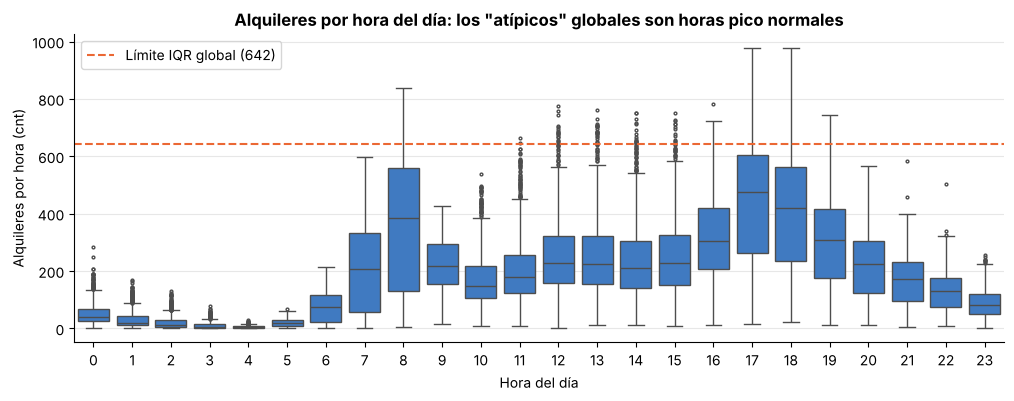

In [9]:
fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(data=df, x='hr', y='cnt', color=AZUL, fliersize=2, ax=ax)
ax.axhline(lim_sup, color=NARANJA, ls='--', lw=1.5, label=f'Límite IQR global ({lim_sup:.0f})')
ax.set(title='Alquileres por hora del día: los "atípicos" globales son horas pico normales',
       xlabel='Hora del día', ylabel='Alquileres por hora (cnt)')
ax.legend()
plt.show()

**Decisiones sobre atípicos.**

- Un 2,9% de las horas (505) supera el límite IQR de `cnt`, y el 82% de ellas son **horas pico de días laborables**. No son errores sino la demanda que más importa a operaciones; **se conservan**. El boxplot por hora muestra que, dentro de cada hora, los valores extremos son pocos.
- Hay 22 registros con **humedad = 0** (todos del 10/03/2011), físicamente imposible: es una falla del sensor. Por ser un solo día (0,1% de los datos) se conservan; su impacto es despreciable.
- `windspeed = 0` aparece en 2.180 registros: puede ser calma real o falta de medición. Se deja tal cual (los modelos de árboles y la red pueden aprender ese valor).
- `weathersit = 4` (lluvia intensa/nieve con niebla) tiene **solo 3 registros**: un modelo no puede aprender nada confiable de 3 casos y, si cae todo en el conjunto de prueba, el codificador vería una categoría desconocida. Siguiendo el diccionario, **se agrupa con la categoría 3** ("mal tiempo").

In [10]:
df['weathersit'] = df['weathersit'].replace(4, 3)

# Variables en unidades reales (solo para gráficos e interpretación), según el diccionario
df['temp_c'] = df['temp'] * 47 - 8
df['hum_pct'] = df['hum'] * 100
df['viento_kmh'] = df['windspeed'] * 67

nombres_estacion = {1: 'Invierno', 2: 'Primavera', 3: 'Verano', 4: 'Otoño'}
nombres_clima = {1: 'Despejado', 2: 'Nublado / niebla', 3: 'Lluvia o nieve'}
df[['temp_c', 'hum_pct', 'viento_kmh']].describe().T[['min', 'mean', 'max']]

,min,mean,max
temp_c,-7.060,15.358,39.000
hum_pct,0.000,62.723,100.000
viento_kmh,0.000,12.737,56.997


## 1.6 Variables nuevas con sentido de negocio

Se crean cuatro variables que traducen lo que un responsable de operaciones ya sabe del negocio:

| Variable | Definición | Por qué |
|---|---|---|
| `fin_de_semana` | 1 si es sábado o domingo (`weekday` 6 o 0) | El patrón de uso cambia: menos viajes al trabajo, más paseos. `workingday` mezcla feriados y fines de semana; esta variable los separa. |
| `hora_pico` | 1 si es día laborable y la hora es 7-9 h o 17-19 h | Son las horas de viajes al trabajo, donde se concentra la demanda y el riesgo de quedarse sin bicicletas. |
| `franja_horaria` | madrugada (0-5), mañana (6-11), tarde (12-17), noche (18-23) | Agrupa horas en turnos operativos (útil para programar personal). |
| `temp_x_hora_pico` | `temp` × `hora_pico` | Interacción temperatura × hora: permite medir si el calor aumenta la demanda de modo distinto en hora pico (viaje obligado) que en el resto del día (viaje opcional). |

In [11]:
df['fin_de_semana'] = df['weekday'].isin([0, 6]).astype(int)
df['hora_pico'] = ((df['workingday'] == 1) & df['hr'].isin([7, 8, 9, 17, 18, 19])).astype(int)
df['franja_horaria'] = pd.cut(df['hr'], bins=[-1, 5, 11, 17, 23],
                              labels=['madrugada', 'mañana', 'tarde', 'noche']).astype(str)
df['temp_x_hora_pico'] = df['temp'] * df['hora_pico']

df.groupby('franja_horaria')['cnt'].agg(['mean', 'sum']).assign(
    participacion=lambda t: t['sum'] / t['sum'].sum()).sort_values('mean', ascending=False)

,mean,sum,participacion
franja_horaria,,,
tarde,295.484,1292742,0.393
noche,225.758,986109,0.299
mañana,208.101,907319,0.276
madrugada,24.909,106509,0.032


In [12]:
pd.DataFrame({
    'demanda media': df.groupby('hora_pico')['cnt'].mean(),
    '% de horas': df['hora_pico'].value_counts(normalize=True).sort_index(),
    '% de alquileres': df.groupby('hora_pico')['cnt'].sum() / df['cnt'].sum()
}).rename(index={0: 'Resto de las horas', 1: 'Hora pico laboral'})

,demanda media,% de horas,% de alquileres
hora_pico,,,
Resto de las horas,146.665,0.828,0.641
Hora pico laboral,396.006,0.172,0.359


**Lectura:** las horas pico laborales son solo el 17% de las horas del año pero concentran el 36% de los alquileres, con una demanda media 2,7 veces mayor que el resto (396 vs. 147 bicicletas por hora). La tarde y la noche suman la mayor parte de los viajes; la madrugada es casi nula (ventana natural para mantenimiento y redistribución).

## 1.7 Gráficos exploratorios

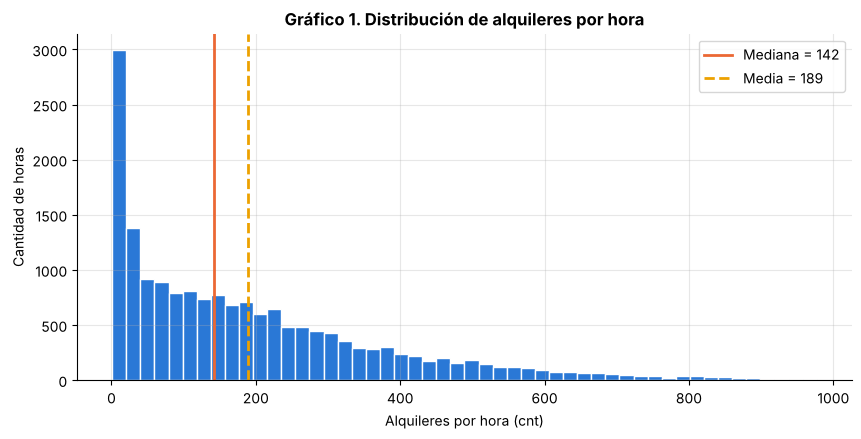

In [13]:
fig, ax = plt.subplots()
ax.hist(df['cnt'], bins=50, color=AZUL, edgecolor='white')
ax.axvline(df['cnt'].median(), color=NARANJA, lw=2, label=f"Mediana = {df['cnt'].median():.0f}")
ax.axvline(df['cnt'].mean(), color=AMARILLO, lw=2, ls='--', label=f"Media = {df['cnt'].mean():.0f}")
ax.set(title='Gráfico 1. Distribución de alquileres por hora', xlabel='Alquileres por hora (cnt)',
       ylabel='Cantidad de horas')
ax.legend()
plt.show()

**Gráfico 1.** Muchas horas tienen pocos alquileres (una de cada cuatro tiene menos de 40) y unas pocas superan los 600. Para operaciones, esto significa que **la flota necesaria la definen las horas pico, no la hora promedio**: dimensionar con la media dejaría sin bicicletas a los usuarios justo cuando más las piden. También indica que un error de 50 bicicletas es enorme a las 3 de la mañana y pequeño a las 18 h; por eso conviene mirar MAE y RMSE junto con el análisis de residuos.

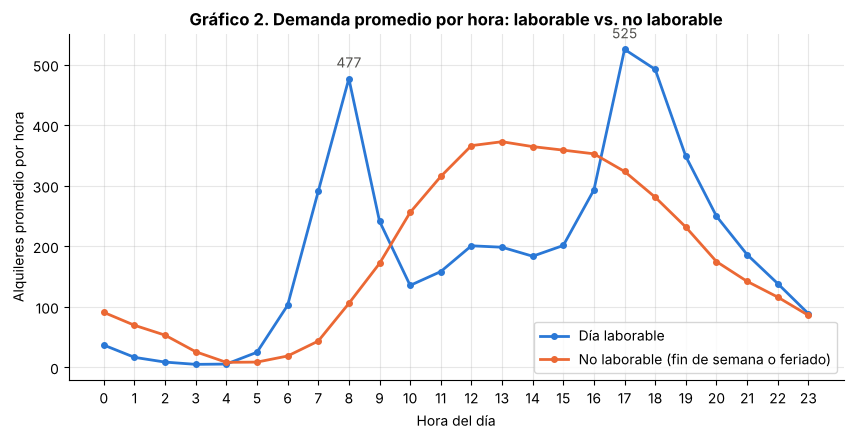

In [14]:
perfil = (df.assign(tipo_dia=df['workingday'].map({1: 'Día laborable', 0: 'No laborable (fin de semana o feriado)'}))
            .groupby(['tipo_dia', 'hr'])['cnt'].mean().unstack(0))
fig, ax = plt.subplots()
ax.plot(perfil.index, perfil['Día laborable'], color=AZUL, lw=2, marker='o', ms=4, label='Día laborable')
ax.plot(perfil.index, perfil['No laborable (fin de semana o feriado)'], color=NARANJA, lw=2, marker='o', ms=4,
        label='No laborable (fin de semana o feriado)')
for h in [8, 17]:
    ax.annotate(f"{perfil.loc[h, 'Día laborable']:.0f}", (h, perfil.loc[h, 'Día laborable']),
                textcoords='offset points', xytext=(0, 8), ha='center', color='#52514e')
ax.set(title='Gráfico 2. Demanda promedio por hora: laborable vs. no laborable', xlabel='Hora del día',
       ylabel='Alquileres promedio por hora', xticks=range(0, 24))
ax.legend()
plt.show()

**Gráfico 2.** Son dos negocios distintos. En los **días laborables** hay dos picos marcados, a las 8 h (~477 alquileres por hora) y a las 17-18 h (~525 y ~490): son viajes al trabajo, de alta concentración y poco tiempo de reacción. En los **días no laborables** la demanda sube gradualmente y forma una meseta entre las 11 y las 17 h (paseos). Operativamente: en días hábiles la redistribución debe estar terminada antes de las 7 h y reforzarse a media tarde; en fines de semana la presión es más pareja y se concentra en el mediodía. Esto justifica incluir la interacción hora × tipo de día (`hora_pico`) en los modelos.

Correlación cnt - temp: 0.40 | cnt - atemp: 0.40 | temp - atemp: 0.99 | cnt - hum: -0.32


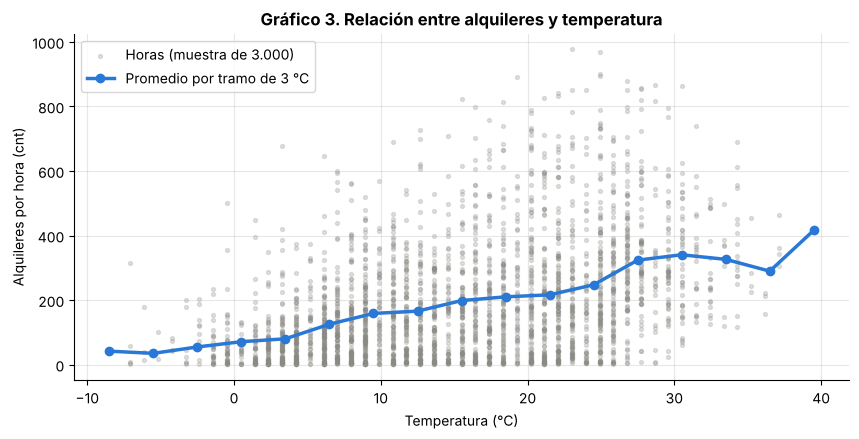

In [15]:
tramos = pd.cut(df['temp_c'], bins=np.arange(-10, 42, 3))
por_tramo = df.groupby(tramos, observed=True)['cnt'].mean()
centros = [i.mid for i in por_tramo.index]

fig, ax = plt.subplots()
muestra = df.sample(3000, random_state=SEED)
ax.scatter(muestra['temp_c'], muestra['cnt'], s=8, alpha=0.25, color=GRIS, label='Horas (muestra de 3.000)')
ax.plot(centros, por_tramo.values, color=AZUL, lw=2.5, marker='o', ms=6, label='Promedio por tramo de 3 °C')
ax.set(title='Gráfico 3. Relación entre alquileres y temperatura', xlabel='Temperatura (°C)',
       ylabel='Alquileres por hora (cnt)')
ax.legend()
plt.show()
print(f"Correlación cnt - temp: {df['cnt'].corr(df['temp']):.2f} | cnt - atemp: {df['cnt'].corr(df['atemp']):.2f} | "
      f"temp - atemp: {df['temp'].corr(df['atemp']):.2f} | cnt - hum: {df['cnt'].corr(df['hum']):.2f}")

**Gráfico 3.** La demanda **crece con la temperatura** hasta alrededor de 30 °C y luego se estanca entre 30 y 36 °C (por encima hay muy pocos registros): el frío desalienta mucho más que el calor. La relación no es lineal, lo que favorece a modelos flexibles (árboles, redes). La sensación térmica (`atemp`) tiene correlación 0,99 con `temp`: aporta prácticamente la misma información, así que **se descarta `atemp`** para no duplicar variables (en un modelo lineal, dos variables casi idénticas vuelven inestables los coeficientes). La humedad tiene correlación negativa (-0,32): días húmedos suelen ser días de lluvia.

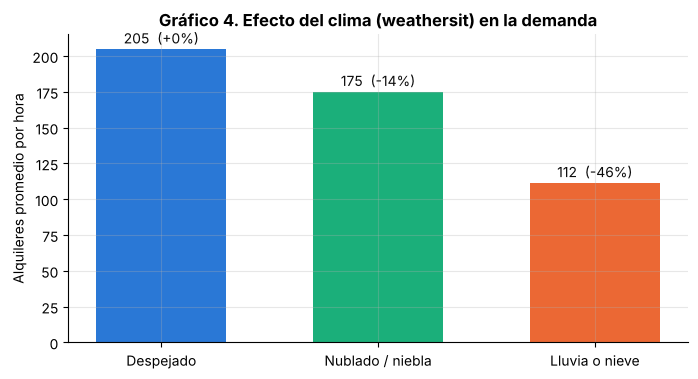

,mean,count,vs_despejado
weathersit,,,
Despejado,204.869,11413,0.000
Nublado / niebla,175.165,4544,-0.145
Lluvia o nieve,111.501,1422,-0.456


In [16]:
clima = df.groupby('weathersit')['cnt'].agg(['mean', 'count']).rename(index=nombres_clima)
clima['vs_despejado'] = clima['mean'] / clima['mean'].iloc[0] - 1
fig, ax = plt.subplots(figsize=(8, 4))
barras = ax.bar(clima.index, clima['mean'], color=[AZUL, VERDE_AGUA, NARANJA], width=0.6)
for b, (_, fila) in zip(barras, clima.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 4,
            f"{fila['mean']:.0f}  ({fila['vs_despejado']:+.0%})", ha='center', color='#0b0b0b')
ax.set(title='Gráfico 4. Efecto del clima (weathersit) en la demanda', ylabel='Alquileres promedio por hora')
plt.show()
clima

**Gráfico 4.** Con cielo nublado o niebla la demanda promedio por hora cae un 14% respecto de un día despejado, y con lluvia o nieve cae un **46%** (casi a la mitad). El clima es, después de la hora, el factor que más mueve la demanda en el corto plazo: un pronóstico de lluvia permite **reducir la redistribución y adelantar mantenimiento** ese día.

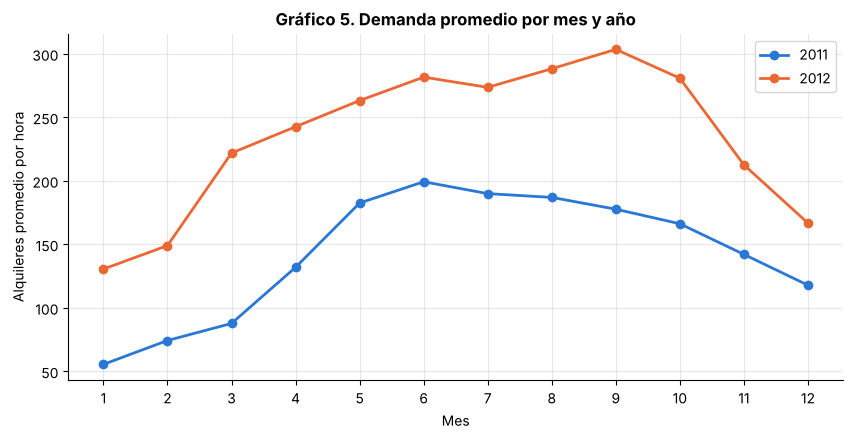

In [17]:
mensual = df.groupby([df['dteday'].dt.year, 'mnth'])['cnt'].mean().unstack(0)
fig, ax = plt.subplots()
ax.plot(mensual.index, mensual[2011], color=AZUL, lw=2, marker='o', label='2011')
ax.plot(mensual.index, mensual[2012], color=NARANJA, lw=2, marker='o', label='2012')
ax.set(title='Gráfico 5. Demanda promedio por mes y año', xlabel='Mes', ylabel='Alquileres promedio por hora',
       xticks=range(1, 13))
ax.legend()
plt.show()

**Gráfico 5.** Hay una **estacionalidad anual** clara (mínimo en enero, máximo entre junio y septiembre) y un **crecimiento fuerte de 2011 a 2012**: todos los meses de 2012 están por encima de los de 2011. Por eso se incluye `yr` como predictor (el diccionario indica que captura el crecimiento) y, en la etapa 5, se separa crecimiento de estacionalidad.

## 1.8 Tratamiento de variables y escalado (decisiones)

- **Categóricas** (`season`, `mnth`, `hr`, `weekday`, `weathersit`, `franja_horaria`): sus códigos numéricos no son cantidades (la hora 23 no es "el doble" que la 11,5 y la demanda por hora tiene dos picos). Para el modelo lineal y la red neuronal se codifican con **One-Hot Encoding**. Para los modelos de árboles se usan **codificadas ordinalmente** (los códigos enteros alcanzan, porque el árbol hace cortes sucesivos y puede aislar cualquier hora), como en los notebooks de la unidad 2.
- **Binarias** (`yr`, `holiday`, `workingday`, `fin_de_semana`, `hora_pico`): ya están en 0/1, pasan sin cambios.
- **Numéricas** (`temp`, `hum`, `windspeed`, `temp_x_hora_pico`): ya vienen normalizadas entre 0 y 1, pero se **estandarizan** con `StandardScaler` para el modelo lineal y la red (la red lo necesita para que el descenso de gradiente converja y la regularización trate igual a todas las variables). Los árboles no necesitan escalado.
- **Excluidas:** `instant`, `dteday` (la información de fecha ya está en `yr`, `mnth`, `weekday`), `atemp` (redundante con `temp`), `casual` y `registered` (fuga de información), y las columnas en unidades reales (solo descriptivas).

El preprocesamiento se define dentro de un `Pipeline` para que se ajuste **solo con los datos de entrenamiento** de cada partición (sin filtrar información del conjunto de prueba).

In [18]:
cat_cols = ['season', 'mnth', 'hr', 'weekday', 'weathersit', 'franja_horaria']
bin_cols = ['yr', 'holiday', 'workingday', 'fin_de_semana', 'hora_pico']
num_cols = ['temp', 'hum', 'windspeed', 'temp_x_hora_pico']
features = cat_cols + bin_cols + num_cols

X = df[features]
y = df['cnt']

# Para modelos lineales y redes: one-hot + estandarización
prep_onehot = ColumnTransformer([
    ('one-hot-encoder', OneHotEncoder(handle_unknown='ignore'), cat_cols),
    ('standard-scaler', StandardScaler(), num_cols)],
    remainder='passthrough')

# Para modelos de árboles: codificación ordinal, sin escalado
prep_arbol = ColumnTransformer([
    ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols)],
    remainder='passthrough')

print('Variables predictoras:', len(features))
print('Columnas tras one-hot:', prep_onehot.fit(X).transform(X[:5]).shape[1])

Variables predictoras: 15
Columnas tras one-hot: 63


# Etapa 2. Modelos de scikit-learn (línea base)

**Problema planteado:** regresión — predecir `cnt` (alquileres en una hora) a partir de calendario, hora y clima.

**Partición:** 80% entrenamiento / 20% prueba con `train_test_split(random_state=42)`. Sobre el conjunto de entrenamiento se hace además **validación cruzada de 5 particiones** (`KFold`, k = 5, con mezcla aleatoria) para estimar la variabilidad del error. El conjunto de prueba no se toca hasta el final de cada evaluación.

> Nota metodológica: la partición aleatoria mezcla horas de distintas fechas, lo que es razonable para la pregunta "¿cuánto se alquila en una hora con estas condiciones?". La evaluación respetando el orden del tiempo (sin mezclar) se hace en la etapa 5, que es la que responde a la pregunta de pronóstico.

**Modelos** (de menor a mayor complejidad): regresión lineal, árbol de decisión, Random Forest y Gradient Boosting por histogramas (`HistGradientBoostingRegressor`), todos dentro de un `Pipeline` preprocesamiento → modelo.

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
print(f'Entrenamiento: {len(X_train):,} horas | Prueba: {len(X_test):,} horas')
print(f'Media de cnt -> entrenamiento: {y_train.mean():.1f} | prueba: {y_test.mean():.1f}')

scoring = {'MAE': 'neg_mean_absolute_error', 'RMSE': 'neg_root_mean_squared_error', 'R2': 'r2'}

def evaluar(nombre, modelo, cv=kf):
    # Validación cruzada (k=5) sobre el entrenamiento, ajuste final en todo el entrenamiento y evaluación en prueba
    cv_res = cross_validate(modelo, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True)
    t0 = time.time()
    modelo.fit(X_train, y_train)
    t_fit = time.time() - t0
    p_tr, p_te = modelo.predict(X_train), modelo.predict(X_test)
    fila = {
        'Modelo': nombre,
        'MAE train': mean_absolute_error(y_train, p_tr),
        'MAE CV': -cv_res['test_MAE'].mean(), 'MAE CV (desv.)': cv_res['test_MAE'].std(),
        'MAE test': mean_absolute_error(y_test, p_te),
        'RMSE train': np.sqrt(mean_squared_error(y_train, p_tr)),
        'RMSE CV': -cv_res['test_RMSE'].mean(),
        'RMSE test': np.sqrt(mean_squared_error(y_test, p_te)),
        'R2 train': r2_score(y_train, p_tr), 'R2 CV': cv_res['test_R2'].mean(),
        'R2 test': r2_score(y_test, p_te),
        'Tiempo ajuste (s)': t_fit,
    }
    return fila, modelo

Entrenamiento: 13,903 horas | Prueba: 3,476 horas
Media de cnt -> entrenamiento: 190.6 | prueba: 185.0


In [20]:
modelos_base = {
    'Regresión lineal': Pipeline([('preprocesador', prep_onehot), ('modelo', LinearRegression())]),
    'Árbol de decisión': Pipeline([('preprocesador', prep_arbol), ('modelo', DecisionTreeRegressor(random_state=SEED))]),
    'Random Forest': Pipeline([('preprocesador', prep_arbol),
                               ('modelo', RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1))]),
    'Gradient Boosting (HGB)': Pipeline([('preprocesador', prep_arbol),
                                         ('modelo', HistGradientBoostingRegressor(random_state=SEED))]),
}

resultados_base, ajustados_base = [], {}
for nombre, modelo in modelos_base.items():
    fila, ajustado = evaluar(nombre, modelo)
    resultados_base.append(fila)
    ajustados_base[nombre] = ajustado

tabla_base = pd.DataFrame(resultados_base).set_index('Modelo')
tabla_base.round(3)

,MAE train,MAE CV,MAE CV (desv.),MAE test,RMSE train,RMSE CV,RMSE test,R2 train,R2 CV,R2 test,Tiempo ajuste (s)
Modelo,,,,,,,,,,,
Regresión lineal,65.829,66.163,1.471,64.332,86.262,86.698,84.657,0.776,0.773,0.774,0.034
Árbol de decisión,0.015,36.295,0.582,35.296,0.599,62.239,60.687,1.000,0.883,0.884,0.062
Random Forest,9.458,26.346,0.582,24.601,15.781,44.039,41.537,0.992,0.941,0.946,1.901
Gradient Boosting (HGB),23.264,26.194,0.700,25.416,36.359,42.121,40.104,0.960,0.946,0.949,0.266


**Lectura de la tabla comparativa (línea base).**

- **Regresión lineal:** MAE ≈ 66 bicicletas por hora y R² ≈ 0,77, iguales en entrenamiento, validación cruzada y prueba → **subajuste** (no sobreajusta, pero es demasiado simple). No puede representar que el efecto de la hora dependa del tipo de día ni la curva de la temperatura.
- **Árbol de decisión sin límites:** error de entrenamiento 0 y MAE de prueba ≈ 35 → **sobreajuste** clásico: memoriza cada hora del entrenamiento (como el árbol del notebook de validación cruzada de la unidad 2). Aun así mejora mucho al lineal.
- **Random Forest** y **Gradient Boosting:** los mejores, con MAE ≈ 25-26 bicicletas y R² ≈ 0,94-0,95 en prueba. El Random Forest tiene una brecha grande entre entrenamiento (MAE ≈ 10) y prueba (≈ 25): sobreajusta algo, pero el promedio de muchos árboles lo compensa. El Gradient Boosting tiene errores de entrenamiento y prueba más parecidos (generaliza mejor) y se entrena en una fracción del tiempo.
- La desviación del MAE entre las 5 particiones es pequeña (menos de 1 bicicleta en los mejores modelos): las conclusiones son estables, no dependen de una partición afortunada. Los valores de validación cruzada y de prueba son muy cercanos, lo que confirma que la prueba es representativa.

### Análisis de residuos

Residuo = valor real − predicción. Un buen modelo tiene residuos centrados en cero, sin patrón respecto de la predicción y sin colas muy largas. Se comparan el modelo lineal y el mejor de la línea base.

Mejor modelo de la línea base según MAE en validación cruzada: Gradient Boosting (HGB)
Regresión lineal: residuo medio = -2.7 | predicciones negativas = 348 | % de horas con error > 100 bicicletas = 20.3%
Gradient Boosting (HGB): residuo medio = -0.0 | predicciones negativas = 54 | % de horas con error > 100 bicicletas = 3.0%


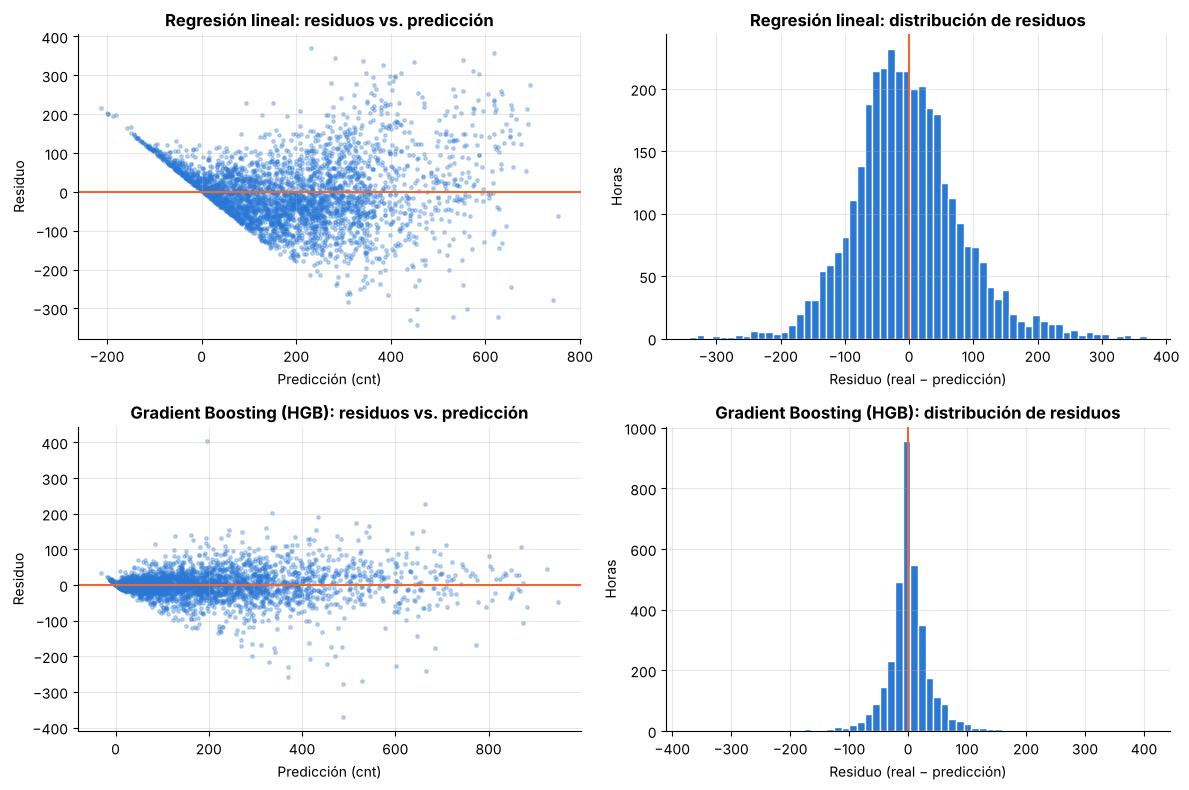

In [21]:
mejor_base = tabla_base['MAE CV'].idxmin()
print('Mejor modelo de la línea base según MAE en validación cruzada:', mejor_base)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for fila_ax, nombre in zip(axes, ['Regresión lineal', mejor_base]):
    pred = ajustados_base[nombre].predict(X_test)
    resid = y_test - pred
    fila_ax[0].scatter(pred, resid, s=6, alpha=0.3, color=AZUL)
    fila_ax[0].axhline(0, color=NARANJA, lw=1.5)
    fila_ax[0].set(title=f'{nombre}: residuos vs. predicción', xlabel='Predicción (cnt)', ylabel='Residuo')
    fila_ax[1].hist(resid, bins=60, color=AZUL, edgecolor='white')
    fila_ax[1].axvline(0, color=NARANJA, lw=1.5)
    fila_ax[1].set(title=f'{nombre}: distribución de residuos', xlabel='Residuo (real − predicción)', ylabel='Horas')
    print(f'{nombre}: residuo medio = {resid.mean():.1f} | predicciones negativas = {(pred < 0).sum()} '
          f'| % de horas con error > 100 bicicletas = {(resid.abs() > 100).mean():.1%}')
plt.tight_layout()
plt.show()

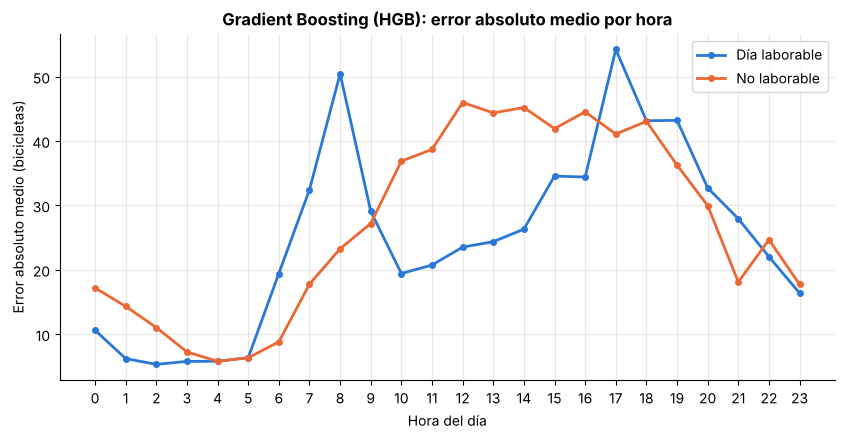

In [22]:
# ¿Dónde se equivoca más el mejor modelo? Error absoluto medio por hora del día y tipo de día
pred_mejor = ajustados_base[mejor_base].predict(X_test)
err = pd.DataFrame({'hr': X_test['hr'], 'workingday': X_test['workingday'], 'cnt': y_test,
                    'error_abs': (y_test - pred_mejor).abs()})
err_hora = err.groupby(['workingday', 'hr'])['error_abs'].mean().unstack(0)
fig, ax = plt.subplots()
ax.plot(err_hora.index, err_hora[1], color=AZUL, lw=2, marker='o', ms=4, label='Día laborable')
ax.plot(err_hora.index, err_hora[0], color=NARANJA, lw=2, marker='o', ms=4, label='No laborable')
ax.set(title=f'{mejor_base}: error absoluto medio por hora', xlabel='Hora del día',
       ylabel='Error absoluto medio (bicicletas)', xticks=range(0, 24))
ax.legend()
plt.show()

**Interpretación de los residuos.**

- **Regresión lineal:** los residuos forman un "embudo" y una curva: subestima las horas de alta demanda (residuos positivos grandes a la derecha) y genera **348 predicciones negativas** (10% de las horas de prueba), algo sin sentido para operaciones. Es la señal gráfica del subajuste: la relación real no es aditiva ni lineal.
- **Mejor modelo de árboles:** los residuos están centrados en cero y mucho más concentrados; su dispersión crece con el nivel de demanda (es natural: equivocarse en un 10% a las 18 h son 50 bicicletas, a las 4 h son 1 o 2). Solo el 3% de las horas tiene un error mayor a 100 bicicletas (vs. 20% en el lineal) y las pocas predicciones negativas (54) son valores apenas por debajo de cero en horas de madrugada, que en la práctica se redondean a 0.
- El error se concentra en las **horas pico de días laborables** y en las tardes de fin de semana, justamente donde la demanda es más alta y más sensible al clima del momento. Para operaciones significa mantener un **margen de seguridad** de flota en esas franjas.

**Conclusión de la etapa 2.** Se recomienda el **Gradient Boosting (HGB)** como modelo base: empata con el Random Forest en validación cruzada (MAE 26,2 vs. 26,3 bicicletas por hora, R² ≈ 0,95; en prueba el Random Forest queda algo mejor, 24,6 vs. 25,4), pero generaliza mejor (menor brecha entre entrenamiento y prueba) y se entrena varias veces más rápido (una fracción de segundo vs. casi 2 s), lo que facilita reentrenarlo con frecuencia y optimizarlo. La regresión lineal queda como referencia interpretable pero insuficiente.

# Etapa 3. Optimización de hiperparámetros

Se optimizan los **tres** modelos de árboles de la etapa anterior, cada uno con la estrategia que mejor se adapta a su espacio de búsqueda (como en los notebooks de la unidad 2):

| Modelo | Estrategia | Espacio de búsqueda | Justificación |
|---|---|---|---|
| Árbol de decisión | `GridSearchCV` (20 combinaciones) | `max_depth` ∈ {5, 10, 15, 20, None}; `min_samples_leaf` ∈ {1, 5, 10, 20} | Son los dos hiperparámetros que regulan la complejidad del árbol (pasar de subajuste a sobreajuste). Con solo 2 hiperparámetros la grilla completa es barata. |
| Random Forest | `GridSearchCV` (8 combinaciones) | `max_depth` ∈ {None, 20}; `min_samples_leaf` ∈ {1, 3}; `max_features` ∈ {0.5, 1.0} | El bosque sobreajustaba (MAE train 10 vs. 25). Se busca limitar la profundidad y el tamaño de hojas, y decorrelacionar los árboles usando una fracción de variables en cada corte. Grilla chica porque cada ajuste es costoso. |
| Gradient Boosting (HGB) | `RandomizedSearchCV` (30 combinaciones al azar) | `learning_rate` ~ U(0,01; 0,31); `max_leaf_nodes` ~ entero[10, 256); `min_samples_leaf` ~ entero[5, 100); `l2_regularization` ~ U(0, 1); `max_iter` ∈ {200, 400, 800} | 5 hiperparámetros que interactúan (tasa de aprendizaje vs. cantidad de árboles y tamaño de cada árbol). La búsqueda aleatoria escala mejor que la grilla con 3 o más hiperparámetros. Rangos centrados en los valores por defecto y ampliados hacia árboles más grandes y más iteraciones. |

Todas las búsquedas usan la misma validación cruzada de 5 particiones y el MAE como criterio.

In [23]:
busquedas = {}

# 1) Árbol de decisión - Grid Search
param_grid_arbol = {'modelo__max_depth': [5, 10, 15, 20, None],
                    'modelo__min_samples_leaf': [1, 5, 10, 20]}
t0 = time.time()
grid_arbol = GridSearchCV(modelos_base['Árbol de decisión'], param_grid=param_grid_arbol, cv=kf,
                          scoring='neg_mean_absolute_error', n_jobs=-1).fit(X_train, y_train)
busquedas['Árbol de decisión'] = (grid_arbol, time.time() - t0, len(grid_arbol.cv_results_['params']))
print(f"Árbol: mejores hiperparámetros {grid_arbol.best_params_} | MAE CV = {-grid_arbol.best_score_:.2f} "
      f"| tiempo = {busquedas['Árbol de decisión'][1]:.0f} s")

Árbol: mejores hiperparámetros {'modelo__max_depth': 15, 'modelo__min_samples_leaf': 5} | MAE CV = 32.84 | tiempo = 4 s


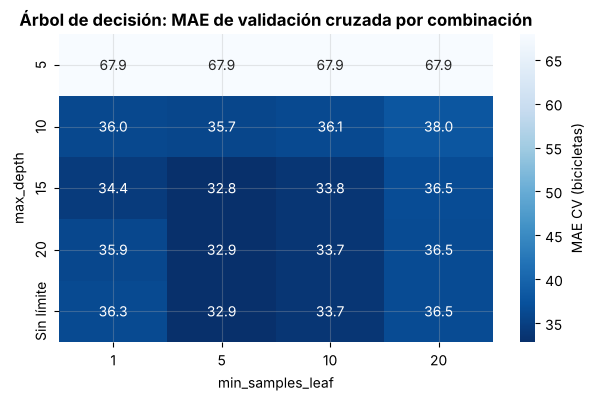

In [24]:
res_arbol = pd.DataFrame(grid_arbol.cv_results_)
mapa = res_arbol.pivot_table(values='mean_test_score', index='param_modelo__max_depth',
                             columns='param_modelo__min_samples_leaf', dropna=False)
mapa.index = mapa.index.map(lambda v: 'Sin límite' if pd.isna(v) else str(int(v)))
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(-mapa, annot=True, fmt='.1f', cmap='Blues_r', cbar_kws={'label': 'MAE CV (bicicletas)'}, ax=ax)
ax.set(title='Árbol de decisión: MAE de validación cruzada por combinación',
       xlabel='min_samples_leaf', ylabel='max_depth')
plt.show()

**Mapa de calor.** Con profundidad 5 el árbol subajusta (MAE ≈ 68, tan malo como la regresión lineal). A partir de profundidad 15 el error se estabiliza, y lo que más ayuda es exigir **hojas con varias observaciones** (`min_samples_leaf` = 5): eso impide que el árbol memorice horas individuales. La mejor combinación es profundidad 15 con hojas de al menos 5 horas (MAE CV = 32,8); exigir hojas de 20 vuelve a empeorar (el árbol se simplifica de más).

In [25]:
# 2) Random Forest - Grid Search
param_grid_rf = {'modelo__max_depth': [None, 20],
                 'modelo__min_samples_leaf': [1, 3],
                 'modelo__max_features': [0.5, 1.0]}
t0 = time.time()
grid_rf = GridSearchCV(modelos_base['Random Forest'], param_grid=param_grid_rf, cv=kf,
                       scoring='neg_mean_absolute_error', n_jobs=1).fit(X_train, y_train)
busquedas['Random Forest'] = (grid_rf, time.time() - t0, len(grid_rf.cv_results_['params']))
print(f"Random Forest: mejores hiperparámetros {grid_rf.best_params_} | MAE CV = {-grid_rf.best_score_:.2f} "
      f"| tiempo = {busquedas['Random Forest'][1]:.0f} s")
pd.DataFrame(grid_rf.cv_results_).sort_values('rank_test_score')[
    ['param_modelo__max_depth', 'param_modelo__min_samples_leaf', 'param_modelo__max_features',
     'mean_test_score', 'std_test_score', 'mean_fit_time']].assign(
    mean_test_score=lambda t: -t['mean_test_score'])

Random Forest: mejores hiperparámetros {'modelo__max_depth': 20, 'modelo__max_features': 0.5, 'modelo__min_samples_leaf': 1} | MAE CV = 26.28 | tiempo = 44 s


,param_modelo__max_depth,param_modelo__min_samples_leaf,param_modelo__max_features,mean_test_score,std_test_score,mean_fit_time
4,20,1,0.500,26.281,0.486,0.836
6,20,1,1.000,26.312,0.576,1.426
2,None,1,1.000,26.346,0.582,1.493
0,None,1,0.500,26.349,0.574,0.890
3,None,3,1.000,26.909,0.618,1.116
7,20,3,1.000,26.912,0.617,1.131
5,20,3,0.500,27.630,0.669,0.618
1,None,3,0.500,27.648,0.730,0.608


In [26]:
# 3) Gradient Boosting (HGB) - Randomized Search
param_dist_hgb = {'modelo__learning_rate': uniform(0.01, 0.3),
                  'modelo__max_leaf_nodes': randint(10, 256),
                  'modelo__min_samples_leaf': randint(5, 100),
                  'modelo__l2_regularization': uniform(0, 1),
                  'modelo__max_iter': [200, 400, 800]}
t0 = time.time()
random_hgb = RandomizedSearchCV(modelos_base['Gradient Boosting (HGB)'], param_distributions=param_dist_hgb,
                                n_iter=30, cv=kf, scoring='neg_mean_absolute_error', n_jobs=-1,
                                random_state=123).fit(X_train, y_train)
busquedas['Gradient Boosting (HGB)'] = (random_hgb, time.time() - t0, 30)
print(f"HGB: MAE CV = {-random_hgb.best_score_:.2f} | tiempo = {busquedas['Gradient Boosting (HGB)'][1]:.0f} s")
print('Mejores hiperparámetros:')
for k, v in random_hgb.best_params_.items():
    print(f'   {k}: {v:.4f}' if isinstance(v, float) else f'   {k}: {v}')

HGB: MAE CV = 24.57 | tiempo = 62 s
Mejores hiperparámetros:
   modelo__l2_regularization: 0.6965
   modelo__learning_rate: 0.0958
   modelo__max_iter: 200
   modelo__max_leaf_nodes: 108
   modelo__min_samples_leaf: 22


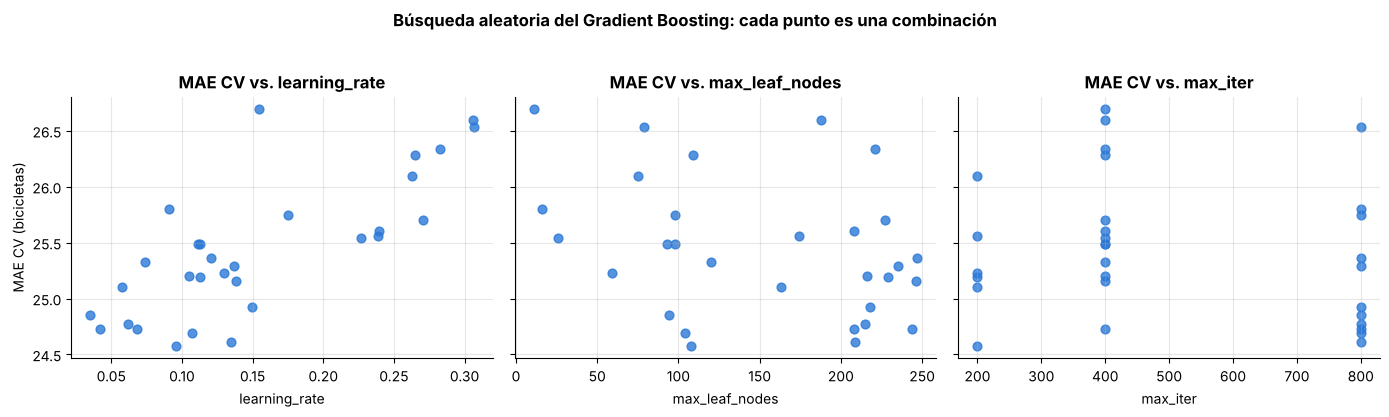

In [27]:
res_hgb = pd.DataFrame(random_hgb.cv_results_)
res_hgb['MAE CV'] = -res_hgb['mean_test_score']
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (param, etiqueta) in zip(axes, [('param_modelo__learning_rate', 'learning_rate'),
                                        ('param_modelo__max_leaf_nodes', 'max_leaf_nodes'),
                                        ('param_modelo__max_iter', 'max_iter')]):
    ax.scatter(res_hgb[param].astype(float), res_hgb['MAE CV'], color=AZUL, s=40, alpha=0.8)
    ax.set(xlabel=etiqueta, title=f'MAE CV vs. {etiqueta}')
axes[0].set_ylabel('MAE CV (bicicletas)')
plt.suptitle('Búsqueda aleatoria del Gradient Boosting: cada punto es una combinación', fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

**Búsqueda aleatoria.** El hiperparámetro con patrón más claro es la **tasa de aprendizaje**: las mejores combinaciones están entre 0,03 y 0,15, y por encima de 0,2 el error sube (pasos demasiado grandes que sobreajustan). La mejor combinación usa árboles **más grandes** que el valor por defecto (108 hojas vs. 31), hojas de al menos 22 horas, regularización L2 de 0,70 y 200 iteraciones. Para `max_leaf_nodes` y `max_iter` no hay un patrón nítido: como en el ejemplo de la cátedra, **no hay un único óptimo** y varias combinaciones distintas quedan a menos de 1 bicicleta del mejor resultado.

In [28]:
# Comparación antes / después: se reevalúan los mejores modelos con el mismo protocolo de la etapa 2
resultados_opt, ajustados_opt = [], {}
for nombre, (busqueda, t_busq, n_comb) in busquedas.items():
    fila, ajustado = evaluar(nombre + ' (optimizado)', busqueda.best_estimator_)
    fila['Tiempo búsqueda (s)'] = t_busq
    fila['Combinaciones probadas'] = n_comb
    resultados_opt.append(fila)
    ajustados_opt[nombre] = ajustado
tabla_opt = pd.DataFrame(resultados_opt).set_index('Modelo')

comparacion = pd.DataFrame({
    'MAE CV antes': tabla_base.loc[list(busquedas), 'MAE CV'].values,
    'MAE CV después': tabla_opt['MAE CV'].values,
    'MAE test antes': tabla_base.loc[list(busquedas), 'MAE test'].values,
    'MAE test después': tabla_opt['MAE test'].values,
    'R2 test antes': tabla_base.loc[list(busquedas), 'R2 test'].values,
    'R2 test después': tabla_opt['R2 test'].values,
    'Tiempo búsqueda (s)': tabla_opt['Tiempo búsqueda (s)'].values,
}, index=list(busquedas))
comparacion['Mejora MAE test (%)'] = (1 - comparacion['MAE test después'] / comparacion['MAE test antes']) * 100
comparacion.round(3)

,MAE CV antes,MAE CV después,MAE test antes,MAE test después,R2 test antes,R2 test después,Tiempo búsqueda (s),Mejora MAE test (%)
Árbol de decisión,36.295,32.842,35.296,30.878,0.884,0.918,3.537,12.517
Random Forest,26.346,26.281,24.601,24.727,0.946,0.947,43.941,-0.514
Gradient Boosting (HGB),26.194,24.573,25.416,22.442,0.949,0.956,62.453,11.700


**¿Cuánto mejoró y se justifica el costo?**

- **Árbol de decisión:** el MAE de prueba baja de 35,3 a 30,9 bicicletas (−12,5%) y el R² sube de 0,88 a 0,92, porque el árbol sin límites sobreajustaba. La búsqueda tardó unos 4 segundos: **se justifica claramente**. Aun optimizado, queda lejos de los modelos de conjunto.
- **Random Forest:** **no mejora** (MAE CV 26,35 → 26,28; en prueba 24,60 → 24,73, prácticamente igual). La configuración por defecto ya estaba en la zona óptima; limitar las hojas (`min_samples_leaf` = 3) empeora. La búsqueda costó unos 45 segundos con solo 8 combinaciones (más de 6 veces lo que costó la del árbol): **el costo no se justifica**, salvo como confirmación de que el modelo por defecto era adecuado. El único beneficio colateral es que `max_features` = 0,5 entrena más rápido.
- **Gradient Boosting (HGB):** el MAE de prueba baja de 25,4 a 22,4 bicicletas por hora (−11,7%), el MAE de validación cruzada de 26,2 a 24,6 y el R² sube a 0,96. La búsqueda de 30 combinaciones tomó alrededor de un minuto. **Es la mejor relación mejora/costo** y queda como el **mejor modelo clásico**: 3 bicicletas menos de error en cada hora del sistema es una mejora operativa visible, sobre todo en las horas pico.

La mejora se confirma tanto en validación cruzada como en el conjunto de prueba (que no participó de la búsqueda), por lo que no es un efecto de "sobreajustar la búsqueda".

# Etapa 4. Redes neuronales

Se usa `MLPRegressor` de scikit-learn (perceptrón multicapa), adecuado para datos tabulares de este tamaño sin necesidad de GPU, dentro del mismo `Pipeline`: **one-hot** para las categóricas y **`StandardScaler`** para las numéricas (requisito para que el descenso de gradiente converja y para que la penalización L2 trate a todas las variables por igual).

**Arquitectura inicial justificada:**

- **Entrada:** 63 neuronas (una por columna tras el one-hot). **Salida:** 1 neurona lineal (regresión).
- **Dos capas ocultas (64, 32):** el análisis exploratorio mostró interacciones (hora × tipo de día, temperatura no lineal). Una capa oculta puede aprenderlas, pero dos capas lo hacen con menos neuronas; la forma de embudo (64 → 32) va condensando la información. Son ~6.200 pesos frente a ~12.500 horas efectivas de entrenamiento: suficiente capacidad sin un riesgo excesivo de memorizar.
- **Activación ReLU:** es la recomendada por defecto, no se satura para valores grandes (la demanda llega a casi 1.000) y entrena rápido.
- **Optimizador `adam`:** el recomendado para conjuntos con miles de observaciones (`lbfgs` es mejor para conjuntos chicos).
- **`early_stopping=True`:** separa el 10% del entrenamiento como validación interna y detiene el entrenamiento cuando el error deja de mejorar durante 10 épocas; es una forma de regularización que evita el sobreajuste y ahorra tiempo.

In [29]:
mlp_base = Pipeline([('preprocesador', prep_onehot),
                     ('modelo', MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu', solver='adam',
                                             early_stopping=True, max_iter=500, random_state=SEED))])
fila_mlp_base, mlp_base = evaluar('Red neuronal MLP (64, 32) inicial', mlp_base)
print(f"Épocas entrenadas: {mlp_base.named_steps['modelo'].n_iter_}")
pd.DataFrame([fila_mlp_base]).set_index('Modelo').round(3)

Épocas entrenadas: 154


,MAE train,MAE CV,MAE CV (desv.),MAE test,RMSE train,RMSE CV,RMSE test,R2 train,R2 CV,R2 test,Tiempo ajuste (s)
Modelo,,,,,,,,,,,
"Red neuronal MLP (64, 32) inicial",23.167,26.127,0.367,25.135,37.431,42.509,40.841,0.958,0.945,0.947,6.203


La red inicial, sin ajustar, ya alcanza un error similar al del Gradient Boosting sin optimizar (MAE CV 26,1 y de prueba 25,1) sin sobreajuste marcado (MAE de entrenamiento 23,2, muy cercano). El *early stopping* detuvo el entrenamiento en la época 154.

## Optimización de hiperparámetros de la red

Se optimizan **cinco** hiperparámetros con `RandomizedSearchCV` (la grilla completa tendría 540 combinaciones):

| Hiperparámetro | Valores | Por qué |
|---|---|---|
| `hidden_layer_sizes` (arquitectura) | (32,), (64,), (64, 32), (128, 64), (128, 64, 32) | Desde una capa chica a tres capas: controla la complejidad. |
| `activation` | relu, tanh | Comparar la activación por defecto con una alternativa suave. |
| `alpha` (regularización L2) | 10⁻⁴ … 10 (escala logarítmica) | Penaliza pesos grandes para evitar el sobreajuste. |
| `learning_rate_init` | 0,001; 0,003; 0,01 | Tasa de aprendizaje: muy chica no converge a tiempo, muy grande oscila. |
| `batch_size` | 64, 200, 512 | Tamaño de lote: lotes chicos actualizan más seguido (más ruido, a veces mejor generalización), lotes grandes son más rápidos. |

`early_stopping` se mantiene activado en todas las combinaciones (es lo que permite que cada ajuste termine en un tiempo razonable). Se usan **15 combinaciones y validación cruzada de 3 particiones** (como en el notebook de redes con scikit-learn), porque cada red tarda bastante más en entrenarse que un árbol; el mejor modelo se reevalúa luego con el protocolo completo de 5 particiones para compararlo en igualdad de condiciones.

In [30]:
param_dist_mlp = {
    'modelo__hidden_layer_sizes': [(32,), (64,), (64, 32), (128, 64), (128, 64, 32)],
    'modelo__activation': ['relu', 'tanh'],
    'modelo__alpha': np.logspace(-4, 1, 6),
    'modelo__learning_rate_init': [0.001, 0.003, 0.01],
    'modelo__batch_size': [64, 200, 512],
}
t0 = time.time()
random_mlp = RandomizedSearchCV(mlp_base, param_distributions=param_dist_mlp, n_iter=15,
                                cv=KFold(n_splits=3, shuffle=True, random_state=SEED),
                                scoring='neg_mean_absolute_error', n_jobs=-1, random_state=123).fit(X_train, y_train)
t_busq_mlp = time.time() - t0
print(f'Tiempo de búsqueda: {t_busq_mlp:.0f} s | MAE CV (3 particiones) del mejor: {-random_mlp.best_score_:.2f}')
print('Mejores hiperparámetros:', random_mlp.best_params_)

res_mlp = pd.DataFrame(random_mlp.cv_results_).sort_values('rank_test_score')
res_mlp['MAE CV'] = -res_mlp['mean_test_score']
res_mlp[['param_modelo__hidden_layer_sizes', 'param_modelo__activation', 'param_modelo__alpha',
         'param_modelo__learning_rate_init', 'param_modelo__batch_size', 'MAE CV', 'std_test_score',
         'mean_fit_time']].head(8)

Tiempo de búsqueda: 187 s | MAE CV (3 particiones) del mejor: 26.23
Mejores hiperparámetros: {'modelo__learning_rate_init': 0.001, 'modelo__hidden_layer_sizes': (64, 32), 'modelo__batch_size': 200, 'modelo__alpha': np.float64(0.1), 'modelo__activation': 'relu'}


,param_modelo__hidden_layer_sizes,param_modelo__activation,param_modelo__alpha,param_modelo__learning_rate_init,param_modelo__batch_size,MAE CV,std_test_score,mean_fit_time
4,"(64, 32)",relu,0.100,0.001,200,26.229,0.666,6.607
11,"(128, 64, 32)",relu,0.010,0.010,512,26.784,0.234,2.270
13,"(128, 64)",relu,0.000,0.010,64,27.332,0.810,4.176
12,"(64,)",relu,0.100,0.001,64,28.465,0.552,11.697
7,"(64,)",relu,0.100,0.010,512,28.968,1.091,2.781
8,"(64,)",tanh,0.001,0.003,200,29.414,0.523,5.597
14,"(128, 64)",tanh,0.000,0.003,64,29.485,0.884,8.649
5,"(64,)",tanh,0.100,0.003,200,29.533,0.321,5.664


Épocas entrenadas: 167 | pesos totales: 6,209


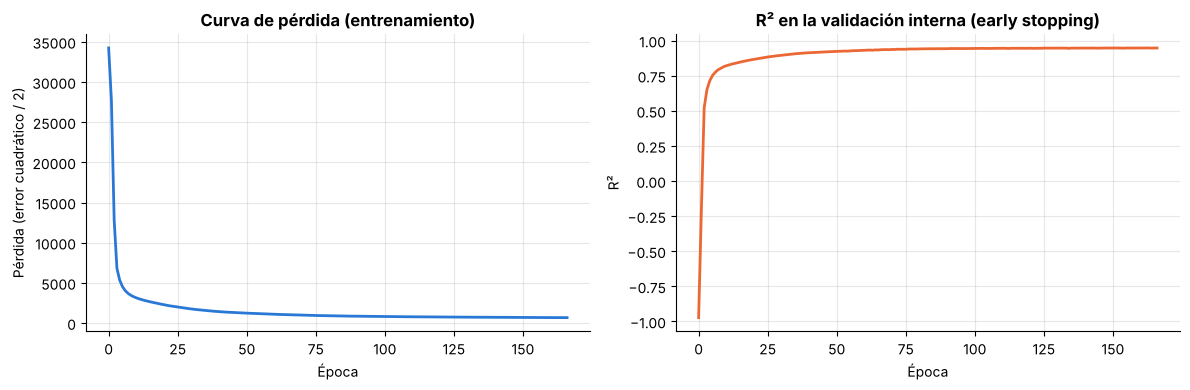

In [31]:
fila_mlp_opt, mlp_opt = evaluar('Red neuronal MLP (optimizada)', random_mlp.best_estimator_)
red = mlp_opt.named_steps['modelo']
print(f'Épocas entrenadas: {red.n_iter_} | pesos totales: {sum(w.size for w in red.coefs_) + sum(b.size for b in red.intercepts_):,}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(red.loss_curve_, color=AZUL, lw=2)
ax[0].set(title='Curva de pérdida (entrenamiento)', xlabel='Época', ylabel='Pérdida (error cuadrático / 2)')
ax[1].plot(red.validation_scores_, color=NARANJA, lw=2)
ax[1].set(title='R² en la validación interna (early stopping)', xlabel='Época', ylabel='R²')
plt.tight_layout()
plt.show()

**Resultado de la búsqueda.** La mejor combinación mantiene la **arquitectura inicial (64, 32) con ReLU**, tasa de aprendizaje 0,001 y lotes de 200, y solo cambia la regularización (`alpha` = 0,1 en lugar de 0,0001). Las 7 mejores combinaciones usan ReLU: `tanh` fue sistemáticamente peor. Las redes de una sola capa también fueron peores (MAE CV ≥ 28,5), lo que confirma que la segunda capa ayuda a capturar las interacciones; agregar una tercera capa (128, 64, 32) no mejoró.

Las curvas muestran el aprendizaje típico: la pérdida baja rápido en las primeras épocas y luego se aplana; el R² de validación interna sube y se estabiliza cerca de 0,95, y el *early stopping* corta el entrenamiento cuando deja de mejorar (evitando seguir ajustando ruido).

## Comparación con los modelos clásicos optimizados

In [32]:
fila_lineal = tabla_base.loc[['Regresión lineal']].reset_index().to_dict('records')[0]
tabla_final = pd.DataFrame([fila_lineal] + resultados_opt + [fila_mlp_base, fila_mlp_opt]).set_index('Modelo')
tabla_final.loc[tabla_final.index[-1], 'Tiempo búsqueda (s)'] = t_busq_mlp
tabla_final.loc[tabla_final.index[-1], 'Combinaciones probadas'] = 15
cols_mostrar = ['MAE train', 'MAE CV', 'MAE CV (desv.)', 'MAE test', 'RMSE test', 'R2 test',
                'Tiempo ajuste (s)', 'Tiempo búsqueda (s)']
tabla_final[cols_mostrar].sort_values('MAE CV').round(3)

,MAE train,MAE CV,MAE CV (desv.),MAE test,RMSE test,R2 test,Tiempo ajuste (s),Tiempo búsqueda (s)
Modelo,,,,,,,,
Gradient Boosting (HGB) (optimizado),15.543,24.573,0.695,22.442,37.196,0.956,1.009,62.453
Red neuronal MLP (optimizada),23.012,26.005,0.439,25.045,40.601,0.948,6.620,187.421
"Red neuronal MLP (64, 32) inicial",23.167,26.127,0.367,25.135,40.841,0.947,6.203,NaN
Random Forest (optimizado),9.881,26.281,0.486,24.727,40.826,0.947,0.949,43.941
Árbol de decisión (optimizado),21.551,32.842,0.353,30.878,51.081,0.918,0.046,3.537
Regresión lineal,65.829,66.163,1.471,64.332,84.657,0.774,0.034,NaN


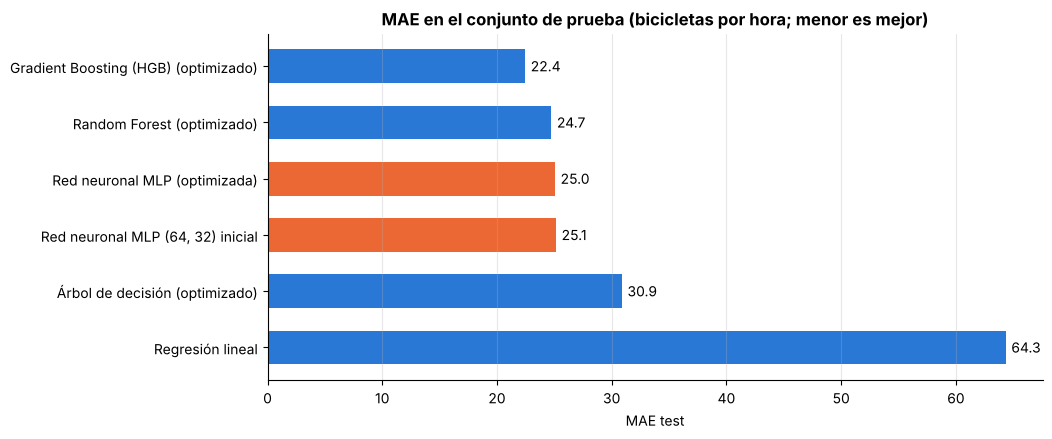

In [33]:
orden = tabla_final.sort_values('MAE test')
colores = [NARANJA if 'Red' in n else AZUL for n in orden.index]
fig, ax = plt.subplots(figsize=(10, 4.5))
barras = ax.barh(orden.index[::-1], orden['MAE test'][::-1], color=colores[::-1], height=0.6)
for b in barras:
    ax.text(b.get_width() + 0.5, b.get_y() + b.get_height() / 2, f'{b.get_width():.1f}', va='center')
ax.set(title='MAE en el conjunto de prueba (bicicletas por hora; menor es mejor)', xlabel='MAE test')
ax.grid(axis='y', visible=False)
plt.show()

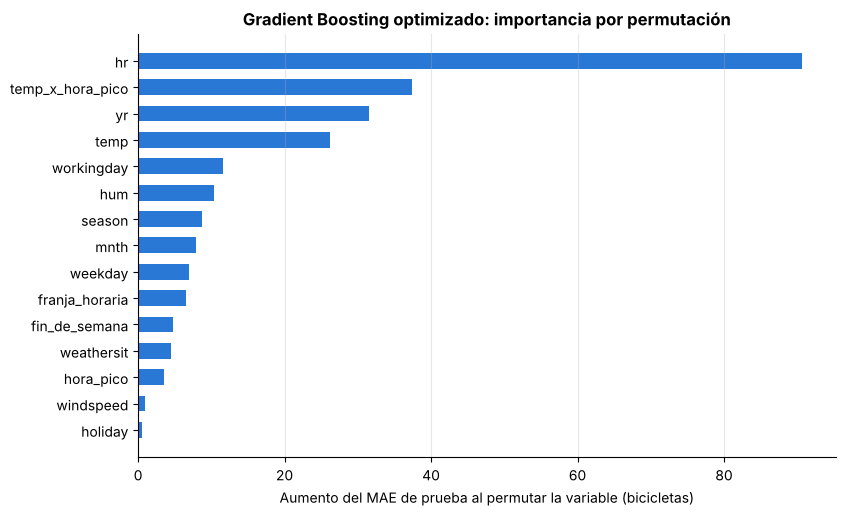

,0
hr,90.700
temp_x_hora_pico,37.400
yr,31.500
temp,26.100
workingday,11.600
hum,10.300
season,8.800
mnth,7.900


In [34]:
# Interpretabilidad: importancia por permutación (cuánto empeora el MAE de prueba si se "desordena" cada variable)
modelo_hgb = ajustados_opt['Gradient Boosting (HGB)']
imp = permutation_importance(modelo_hgb, X_test, y_test, scoring='neg_mean_absolute_error',
                             n_repeats=5, random_state=SEED, n_jobs=-1)
importancia = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(importancia.index, importancia.values, color=AZUL, height=0.6)
ax.set(title='Gradient Boosting optimizado: importancia por permutación',
       xlabel='Aumento del MAE de prueba al permutar la variable (bicicletas)')
ax.grid(axis='y', visible=False)
plt.show()
importancia.sort_values(ascending=False).head(8).round(1)

**Discusión: ¿se justifica la mayor complejidad de la red?**

- **Desempeño:** la optimización casi no mejoró a la red (MAE de prueba 25,1 → 25,0; MAE CV 26,1 → 26,0). La red queda al nivel del Random Forest, pero **no supera al Gradient Boosting optimizado**, que tiene el menor error en validación cruzada (24,6) y en prueba (22,4, es decir 2,6 bicicletas por hora menos que la red). En datos tabulares de este tamaño, los modelos de árboles en conjunto suelen ser tan buenos o mejores que una red.
- **Tiempo de entrenamiento:** la red tarda unos 7 s en entrenarse contra alrededor de 1 s del Gradient Boosting, y su búsqueda de hiperparámetros fue la más cara del trabajo (unos 3 minutos) aun con la mitad de combinaciones y 3 particiones en lugar de 5.
- **Esfuerzo de ajuste:** la red exigió escalado obligatorio, one-hot, *early stopping* y cinco hiperparámetros sensibles entre sí; el Gradient Boosting funciona bien con valores por defecto y no requiere escalado.
- **Interpretabilidad:** ninguna de las dos es transparente como una regresión lineal, pero para el modelo de árboles la importancia por permutación (gráfico anterior) es directa de explicar: **la hora del día** es por lejos la variable más importante (si se desordena, el error sube unas 91 bicicletas), seguida de la interacción **temperatura × hora pico** creada en la etapa 1 (37), el **año** (crecimiento, 32), la **temperatura** (26), si el día es **laborable** (12) y la **humedad** (10). La red no ofrece una ventaja en este punto.

**Conclusión:** la mayor complejidad de la red **no se justifica** para este problema. Se recomienda el **Gradient Boosting optimizado** como modelo de producción para la predicción horaria. La red sería una opción a revisar si se incorporaran datos de otro tipo (por ejemplo, secuencias largas por estación o información no tabular).

# Etapa 5. Series de tiempo

Se trabaja con la demanda **diaria**: `cnt` sumado por día, 731 observaciones ordenadas por `dteday` (1/1/2011 al 31/12/2012). Esta serie responde a la pregunta de planificación de la gerencia: cuántos alquileres esperar en el próximo trimestre.

In [35]:
diario = (df.groupby('dteday')
            .agg(cnt=('cnt', 'sum'), holiday=('holiday', 'first'), workingday=('workingday', 'first'),
                 temp=('temp', 'mean'), hum=('hum', 'mean'), windspeed=('windspeed', 'mean'),
                 weathersit=('weathersit', 'max'))
            .sort_index().asfreq('D'))
serie = diario['cnt']
print(f'Observaciones: {len(serie)} | desde {serie.index.min().date()} hasta {serie.index.max().date()} '
      f'| días faltantes: {serie.isna().sum()}')
serie.describe().to_frame('alquileres por día').T

Observaciones: 731 | desde 2011-01-01 hasta 2012-12-31 | días faltantes: 0


,count,mean,std,min,25%,50%,75%,max
alquileres por día,731.000,"4,504.349","1,937.211",22.000,"3,152.000","4,548.000","5,956.000","8,714.000"


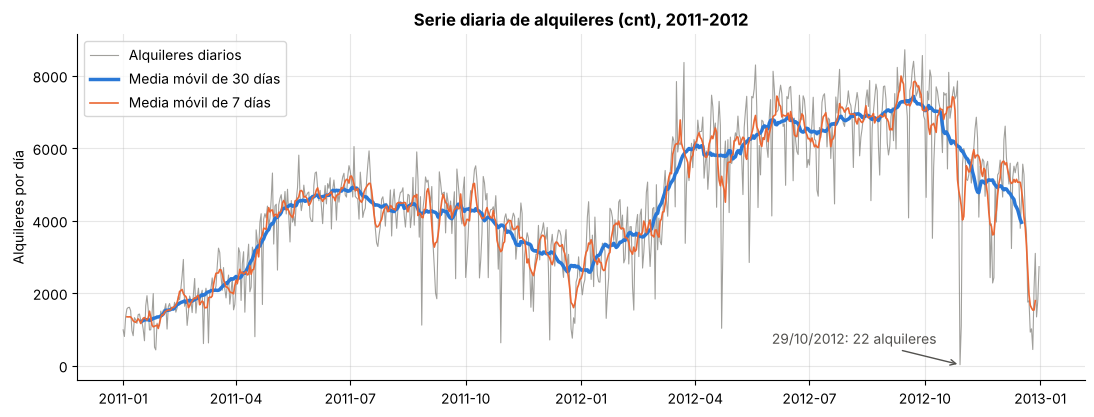

In [36]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(serie.index, serie, color=GRIS, lw=0.8, alpha=0.8, label='Alquileres diarios')
ax.plot(serie.index, serie.rolling(30, center=True).mean(), color=AZUL, lw=2.5, label='Media móvil de 30 días')
ax.plot(serie.index, serie.rolling(7, center=True).mean(), color=NARANJA, lw=1.2, label='Media móvil de 7 días')
ax.annotate('29/10/2012: 22 alquileres', xy=(pd.Timestamp('2012-10-29'), 22), xytext=(pd.Timestamp('2012-06-01'), 600),
            arrowprops=dict(arrowstyle='->', color='#52514e'), color='#52514e')
ax.set(title='Serie diaria de alquileres (cnt), 2011-2012', ylabel='Alquileres por día')
ax.legend(loc='upper left')
plt.show()

**Componentes que se observan:**

- **Tendencia:** creciente. La media móvil de 30 días pasa de ~1.200-2.000 alquileres diarios a inicios de 2011 a ~7.000 a mediados de 2012. El crecimiento parece desacelerarse hacia fines de 2012.
- **Estacionalidad anual:** valle en invierno (diciembre-febrero) y meseta alta entre mayo y septiembre, repetida en ambos años y con mayor amplitud en 2012 (la oscilación crece con el nivel → conviene un modelo **multiplicativo**: tendencia × índice estacional).
- **Estacionalidad semanal:** oscilaciones cortas visibles en la media móvil de 7 días (diferencias entre días de semana y fines de semana).
- **Ruido:** caídas bruscas de un día por lluvia o eventos. El caso extremo es el **29/10/2012, con solo 22 alquileres** (coincide con el paso del huracán Sandy por Washington, cuando el sistema suspendió el servicio) y el 30/10. Son irregularidades que ningún modelo de calendario puede anticipar.

## 5.1 Descomposición clásica multiplicativa y desestacionalización

Modelo: **Y(t) = T(t) × S_mes(t) × S_día_semana(t) × I(t)**

- **T(t), tendencia:** recta estimada por regresión sobre el tiempo (tendencia determinística de grado 1; la cátedra advierte no usar polinomios de grado mayor porque dominan las proyecciones).
- **S_mes, índice estacional anual:** promedio, para cada mes, del cociente entre la serie y la tendencia (Y/T), normalizado para que el promedio de los 12 índices sea 1.
- **S_día, índice estacional semanal:** promedio por día de la semana del cociente Y / (T × S_mes), normalizado a promedio 1.
- **I(t), irregular/ruido:** lo que queda: Y / (T × S).

Como la tendencia estimada sobre la serie original está sesgada por la estacionalidad (si los datos terminan en temporada alta la recta se inclina de más), se itera: se estima la tendencia sobre la serie **desestacionalizada** (Y / S) y se recalculan los índices, hasta que se estabilizan (3 pasadas). Se usan índices mensuales en lugar de una media móvil centrada de 365 días porque con solo dos años esa media perdería seis meses en cada extremo de la serie.

In [37]:
def descomposicion_clasica(y, n_iter=3):
    # Descomposición multiplicativa: tendencia lineal x índice mensual x índice de día de semana
    t = np.arange(len(y)).reshape(-1, 1)
    S = np.ones(len(y))
    for _ in range(n_iter):
        tendencia = LinearRegression().fit(t, (y / S).values)
        T = tendencia.predict(t)
        ratio = y / T
        idx_mes = ratio.groupby(y.index.month).mean()
        idx_mes = idx_mes / idx_mes.mean()
        ratio2 = y / (T * y.index.month.map(idx_mes).values)
        idx_dia = ratio2.groupby(y.index.dayofweek).mean()
        idx_dia = idx_dia / idx_dia.mean()
        S = y.index.month.map(idx_mes).values * y.index.dayofweek.map(idx_dia).values
    componentes = pd.DataFrame({'original': y, 'tendencia': T, 'estacional': S,
                                'irregular': y / (T * S), 'desestacionalizada': y / S}, index=y.index)
    return tendencia, idx_mes, idx_dia, componentes

def proyectar_descomposicion(tendencia, idx_mes, idx_dia, fechas, t_inicio):
    t = np.arange(t_inicio, t_inicio + len(fechas)).reshape(-1, 1)
    return pd.Series(tendencia.predict(t) * fechas.month.map(idx_mes).values * fechas.dayofweek.map(idx_dia).values,
                     index=fechas)

tend_total, idx_mes_total, idx_dia_total, comp = descomposicion_clasica(serie)
print(f'Tendencia: {tend_total.intercept_:,.0f} alquileres/día al inicio + {tend_total.coef_[0]:.2f} por día '
      f'(≈ {tend_total.coef_[0] * 365:,.0f} alquileres diarios más por año)')

Tendencia: 2,308 alquileres/día al inicio + 6.01 por día (≈ 2,193 alquileres diarios más por año)


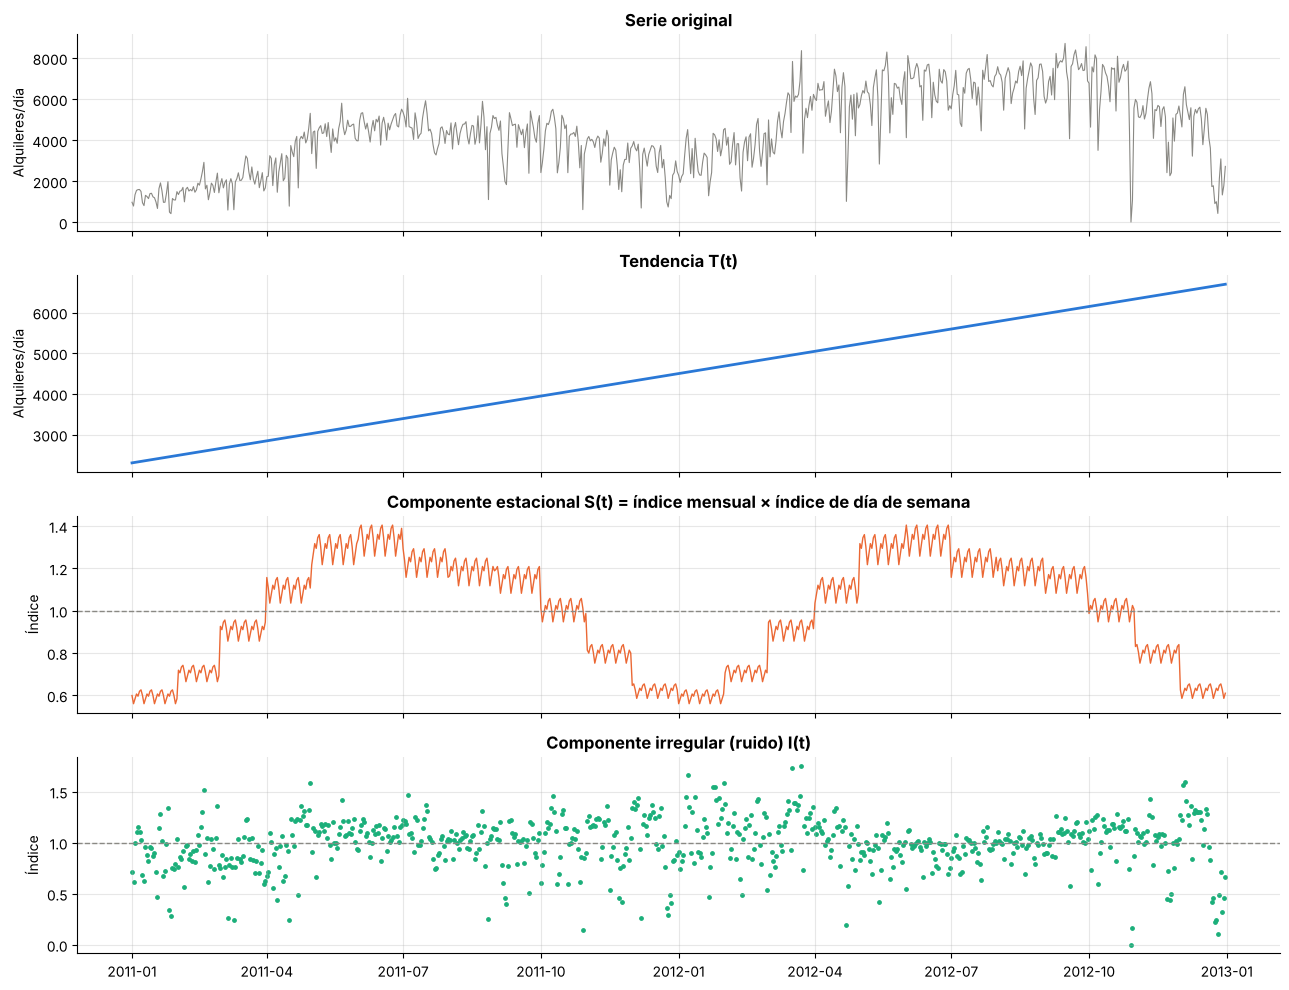

In [38]:
fig, axes = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
axes[0].plot(comp.index, comp['original'], color=GRIS, lw=0.8)
axes[0].set(title='Serie original', ylabel='Alquileres/día')
axes[1].plot(comp.index, comp['tendencia'], color=AZUL, lw=2)
axes[1].set(title='Tendencia T(t)', ylabel='Alquileres/día')
axes[2].plot(comp.index, comp['estacional'], color=NARANJA, lw=1)
axes[2].axhline(1, color=GRIS, lw=1, ls='--')
axes[2].set(title='Componente estacional S(t) = índice mensual × índice de día de semana', ylabel='Índice')
axes[3].scatter(comp.index, comp['irregular'], color=VERDE_AGUA, s=6)
axes[3].axhline(1, color=GRIS, lw=1, ls='--')
axes[3].set(title='Componente irregular (ruido) I(t)', ylabel='Índice')
plt.tight_layout()
plt.show()

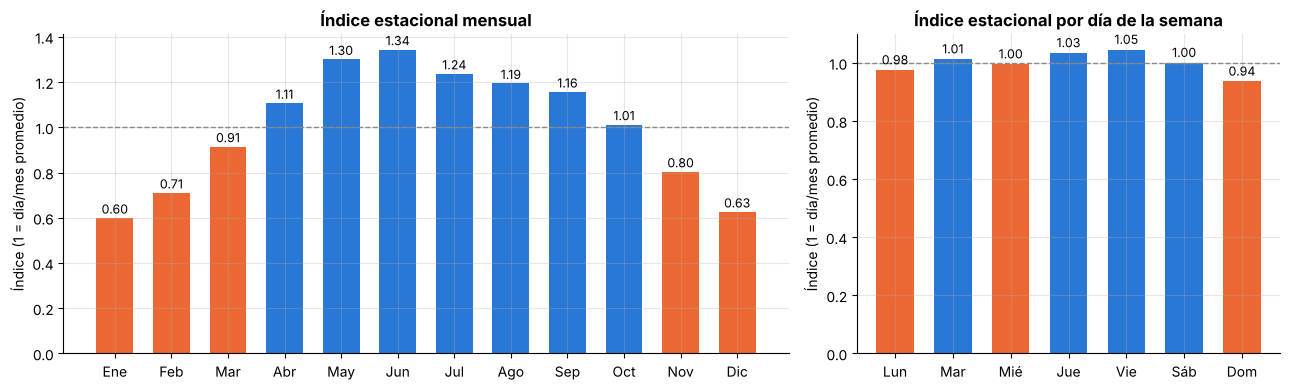

,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
índice mensual,0.599,0.710,0.914,1.106,1.300,1.343,1.237,1.194,1.156,1.012,0.803,0.626


In [39]:
meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
dias = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [12, 7]})
for ax, idx, etiquetas, titulo in [(axes[0], idx_mes_total, meses, 'Índice estacional mensual'),
                                    (axes[1], idx_dia_total, dias, 'Índice estacional por día de la semana')]:
    colores = [AZUL if v >= 1 else NARANJA for v in idx.values]
    barras = ax.bar(etiquetas, idx.values, color=colores, width=0.65)
    ax.axhline(1, color=GRIS, lw=1, ls='--')
    for b in barras:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.02, f'{b.get_height():.2f}', ha='center', fontsize=9)
    ax.set(title=titulo, ylabel='Índice (1 = día/mes promedio)')
plt.tight_layout()
plt.show()
pd.DataFrame({'índice mensual': idx_mes_total.values}, index=meses).T.round(3)

**Índices estacionales.** Un día de enero tiene una demanda de alrededor del **60%** de un día promedio (índice 0,60), y diciembre y febrero rondan el 63-71%, mientras que mayo-septiembre están entre un **16% y un 34% por encima** del promedio (junio es el máximo, 1,34). El mejor mes más que duplica al peor. El patrón semanal es mucho más suave: jueves y viernes un 3-5% por encima y domingo un 6% por debajo: **en el total diario, el día de la semana importa poco** (los días hábiles y los fines de semana tienen volúmenes parecidos, aunque, como se vio en la etapa 1, con perfiles horarios muy diferentes). Para la planificación, el calendario anual es lo que define la flota necesaria.

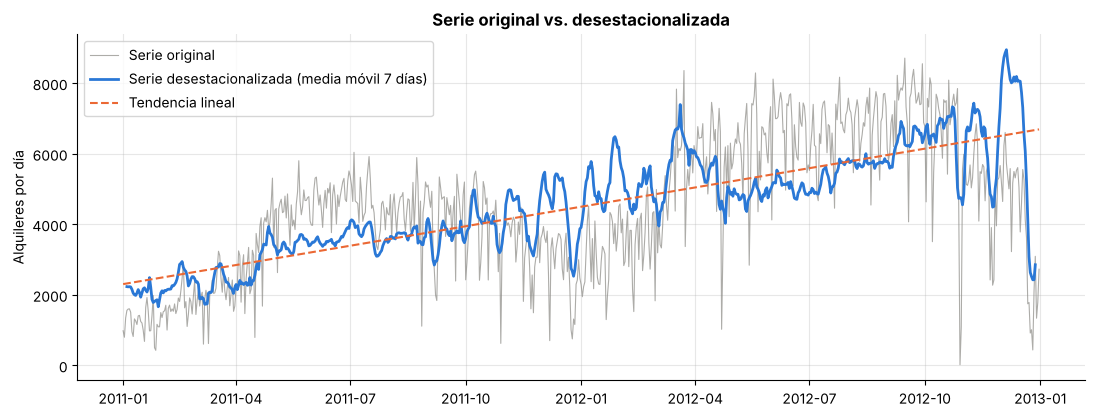

In [40]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(comp.index, comp['original'], color=GRIS, lw=0.8, alpha=0.7, label='Serie original')
ax.plot(comp.index, comp['desestacionalizada'].rolling(7, center=True).mean(), color=AZUL, lw=2,
        label='Serie desestacionalizada (media móvil 7 días)')
ax.plot(comp.index, comp['tendencia'], color=NARANJA, lw=1.5, ls='--', label='Tendencia lineal')
ax.set(title='Serie original vs. desestacionalizada', ylabel='Alquileres por día')
ax.legend(loc='upper left')
plt.show()

In [41]:
anual = pd.DataFrame({
    'Original': comp['original'].groupby(comp.index.year).sum(),
    'Desestacionalizada': comp['desestacionalizada'].groupby(comp.index.year).sum()})
anual.loc['Crecimiento 2012 vs 2011 (%)'] = (anual.loc[2012] / anual.loc[2011] - 1) * 100
print('Totales anuales de alquileres y crecimiento:')
display(anual.round(1))

# Comparación dentro del año: enero vs. julio (misma cantidad de días, distinta estación)
def media_mes(col, anio, mes):
    return comp.loc[(comp.index.year == anio) & (comp.index.month == mes), col].mean()

filas = []
for desc, (a1, m1), (a2, m2) in [('Ene-2011 → Jul-2011', (2011, 1), (2011, 7)),
                                  ('Jul-2011 → Ene-2012', (2011, 7), (2012, 1)),
                                  ('Ene-2011 → Ene-2012 (interanual)', (2011, 1), (2012, 1)),
                                  ('Jul-2011 → Jul-2012 (interanual)', (2011, 7), (2012, 7))]:
    filas.append({'Comparación': desc,
                  'Variación original (%)': (media_mes('original', a2, m2) / media_mes('original', a1, m1) - 1) * 100,
                  'Variación desestacionalizada (%)': (media_mes('desestacionalizada', a2, m2) /
                                                       media_mes('desestacionalizada', a1, m1) - 1) * 100})
var = pd.DataFrame(filas).set_index('Comparación')
var['Parte explicada por la estacionalidad (p.p.)'] = var['Variación original (%)'] - var['Variación desestacionalizada (%)']
var.round(1)

,Original,Desestacionalizada
dteday,,
2011,"1,243,103.000","1,227,624.500"
2012,"2,049,576.000","2,062,935.400"
Crecimiento 2012 vs 2011 (%),64.900,68.000


Totales anuales de alquileres y crecimiento:


,Variación original (%),Variación desestacionalizada (%),Parte explicada por la estacionalidad (p.p.)
Comparación,,,
Ene-2011 → Jul-2011,270.100,79.400,190.700
Jul-2011 → Ene-2012,-31.600,41.000,-72.600
Ene-2011 → Ene-2012 (interanual),153.300,153.000,0.300
Jul-2011 → Jul-2012 (interanual),44.100,44.100,-0.100


**¿Cuánto del aumento es crecimiento genuino y cuánto es estacionalidad?**

- **Año contra año completo:** los alquileres pasaron de ≈ 1,24 a ≈ 2,05 millones (**+64,9%**). Desestacionalizada, la serie crece prácticamente lo mismo (+68,0%). La razón es que **cada año completo contiene un ciclo estacional completo**: los meses buenos y malos se compensan, así que **casi todo el aumento anual es crecimiento genuino** del sistema (más usuarios y más uso), no estacionalidad. La pequeña diferencia viene de cómo cae el calendario (cantidad de cada día de la semana, año bisiesto) y de la demanda real de cada mes respecto de su índice.
- **Donde la estacionalidad sí engaña es en comparaciones dentro del año.** De enero a julio de 2011 la demanda diaria promedio subió un 270% en la serie original, pero desestacionalizada la suba es del 79%: **unos 190 puntos porcentuales de ese salto (más de dos tercios) son efecto verano** y el resto es crecimiento genuino. De julio de 2011 a enero de 2012 la serie original muestra una caída del 32%, mientras que la desestacionalizada muestra un **crecimiento del 41%**: el negocio crecía aunque los números de invierno parecieran malos.
- Las comparaciones interanuales (mismo mes, distinto año) dan el mismo resultado en ambas series (+153% enero contra enero, +44% julio contra julio), porque comparan meses con el mismo índice estacional: ahí todo el cambio es genuino. Notar además que el crecimiento interanual se va reduciendo a lo largo de 2012.

**Mensaje para la gerencia:** para evaluar el desempeño del negocio hay que comparar contra el mismo mes del año anterior o usar la serie desestacionalizada; comparar un mes de invierno con uno de verano lleva a conclusiones equivocadas.

## 5.2 Pronóstico y validación temporal (últimos 90 días como prueba)

Se reservan los **últimos 90 días** (3/10/2012 al 31/12/2012) como conjunto de prueba, **sin mezclar al azar**: todos los modelos se estiman solo con los 641 días anteriores y se proyectan 90 días hacia adelante de una sola vez (sin ver ningún dato real del período de prueba).

Enfoques comparados:

1. **Descomposición clásica** (tendencia × índice estacional), con la tendencia y los índices estimados **solo con los datos anteriores** al período de prueba.
2. **Modelo de machine learning (regresión lineal con variables de calendario):** predictores `tendencia` (contador de días), mes y día de la semana (one-hot) y feriado/día laborable, en un `Pipeline` como en el notebook de predicción de la unidad 4. Usa solo información conocida de antemano (el calendario), por lo que sirve para proyectar un trimestre futuro.
3. **Gradient Boosting con las mismas variables de calendario**, para mostrar una limitación importante de los árboles en series con tendencia.
4. **Regresión lineal con calendario + clima observado** (temperatura, humedad, viento y tipo de clima del día). **No es un pronóstico real**: usa el clima que efectivamente ocurrió, que no se conoce con un trimestre de anticipación. Se incluye como referencia para medir cuánto error se debe al clima.

**Métricas:** MAE (alquileres/día), RMSE y MAPE = promedio de |real − pronóstico| / real × 100.

In [42]:
H = 90
train_s, test_s = serie.iloc[:-H], serie.iloc[-H:]
print(f'Entrenamiento: {train_s.index.min().date()} a {train_s.index.max().date()} ({len(train_s)} días)')
print(f'Prueba:        {test_s.index.min().date()} a {test_s.index.max().date()} ({len(test_s)} días)')

def metricas(real, pred):
    e = real - pred
    return {'MAE': np.mean(np.abs(e)), 'RMSE': np.sqrt(np.mean(e ** 2)), 'MAPE (%)': np.mean(np.abs(e) / real) * 100}

pronosticos = {}

# 1) Descomposición clásica estimada solo con entrenamiento
tend_tr, idx_mes_tr, idx_dia_tr, comp_tr = descomposicion_clasica(train_s)
pronosticos['1. Descomposición clásica'] = proyectar_descomposicion(tend_tr, idx_mes_tr, idx_dia_tr, test_s.index, len(train_s))
print(f'Pendiente de la tendencia (entrenamiento): {tend_tr.coef_[0]:.2f} alquileres/día por día')

Entrenamiento: 2011-01-01 a 2012-10-02 (641 días)
Prueba:        2012-10-03 a 2012-12-31 (90 días)
Pendiente de la tendencia (entrenamiento): 6.23 alquileres/día por día


In [43]:
# Variables de calendario (conocidas de antemano) y de clima
Xs = pd.DataFrame({'tendencia': np.arange(len(serie)), 'mes': serie.index.month, 'dia_semana': serie.index.dayofweek,
                   'holiday': diario['holiday'].values, 'workingday': diario['workingday'].values},
                  index=serie.index)
Xs_clima = Xs.join(diario[['temp', 'hum', 'windspeed', 'weathersit']])
Xs_tr, Xs_te = Xs.iloc[:-H], Xs.iloc[-H:]
Xc_tr, Xc_te = Xs_clima.iloc[:-H], Xs_clima.iloc[-H:]

prep_cal = ColumnTransformer([('cate', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['mes', 'dia_semana']),
                              ('num', 'passthrough', ['tendencia', 'holiday', 'workingday'])])
prep_clima = ColumnTransformer([('cate', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
                                 ['mes', 'dia_semana', 'weathersit']),
                                ('num', StandardScaler(), ['tendencia', 'holiday', 'workingday', 'temp', 'hum', 'windspeed'])])

ml_cal = Pipeline([('procesado', prep_cal), ('estimación', LinearRegression())]).fit(Xs_tr, train_s)
pronosticos['2. ML: regresión lineal (calendario)'] = pd.Series(ml_cal.predict(Xs_te), index=test_s.index)

hgb_cal = Pipeline([('procesado', prep_cal), ('estimación', HistGradientBoostingRegressor(random_state=SEED))]).fit(Xs_tr, train_s)
pronosticos['3. ML: Gradient Boosting (calendario)'] = pd.Series(hgb_cal.predict(Xs_te), index=test_s.index)

ml_clima = Pipeline([('procesado', prep_clima), ('estimación', LinearRegression())]).fit(Xc_tr, train_s)
pronosticos['4. Referencia: lineal con clima observado'] = pd.Series(ml_clima.predict(Xc_te), index=test_s.index)

# Validación cruzada temporal del modelo de calendario dentro del entrenamiento (TimeSeriesSplit)
cv_ts = cross_validate(Pipeline([('procesado', prep_cal), ('estimación', LinearRegression())]), Xs_tr, train_s,
                       cv=TimeSeriesSplit(n_splits=5), scoring=['neg_mean_absolute_error', 'neg_root_mean_squared_error'])
print(f"TimeSeriesSplit (5 cortes, solo entrenamiento) - regresión lineal calendario: "
      f"MAE = {-cv_ts['test_neg_mean_absolute_error'].mean():,.0f} ± {cv_ts['test_neg_mean_absolute_error'].std():,.0f}")

TimeSeriesSplit (5 cortes, solo entrenamiento) - regresión lineal calendario: MAE = 1,124 ± 173


In [44]:
# Tabla de errores de proyección en los 90 días de prueba
atipicos = pd.to_datetime(['2012-10-29', '2012-10-30'])
mascara = ~test_s.index.isin(atipicos)
filas = []
for nombre, pred in pronosticos.items():
    m_all = metricas(test_s.values, pred.values)
    m_sin = metricas(test_s.values[mascara], pred.values[mascara])
    filas.append({'Enfoque': nombre, **m_all,
                  'MAPE sin 29-30/10 (%)': m_sin['MAPE (%)'], 'MAE sin 29-30/10': m_sin['MAE'],
                  'Pronóstico medio/día': pred.mean(), 'Real medio/día': test_s.mean()})
tabla_errores = pd.DataFrame(filas).set_index('Enfoque')
tabla_errores.round(1)

,MAE,RMSE,MAPE (%),MAPE sin 29-30/10 (%),MAE sin 29-30/10,Pronóstico medio/día,Real medio/día
Enfoque,,,,,,,
1. Descomposición clásica,"1,248.900","1,664.300",361.000,44.500,"1,146.700","5,242.800","5,153.300"
2. ML: regresión lineal (calendario),"1,285.500","1,823.600",374.700,52.300,"1,182.800","5,722.200","5,153.300"
3. ML: Gradient Boosting (calendario),"2,242.000","2,826.100",410.700,88.700,"2,161.500","7,119.700","5,153.300"
4. Referencia: lineal con clima observado,"1,030.800","1,460.300",291.000,40.800,953.500,"5,521.300","5,153.300"


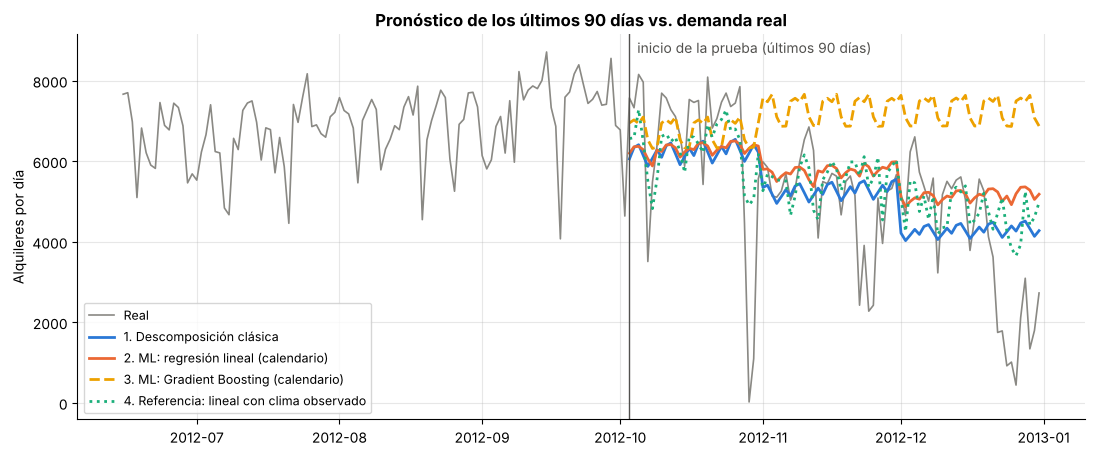

In [45]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(serie.index[-200:], serie.iloc[-200:], color=GRIS, lw=1.2, label='Real')
estilos = {'1. Descomposición clásica': (AZUL, '-'), '2. ML: regresión lineal (calendario)': (NARANJA, '-'),
           '3. ML: Gradient Boosting (calendario)': (AMARILLO, '--'),
           '4. Referencia: lineal con clima observado': (VERDE_AGUA, ':')}
for nombre, pred in pronosticos.items():
    color, ls = estilos[nombre]
    ax.plot(pred.index, pred, color=color, ls=ls, lw=2, label=nombre)
ax.axvline(test_s.index[0], color='#52514e', lw=1)
ax.text(test_s.index[0], ax.get_ylim()[1] * 0.95, '  inicio de la prueba (últimos 90 días)', color='#52514e')
ax.set(title='Pronóstico de los últimos 90 días vs. demanda real', ylabel='Alquileres por día')
ax.legend(loc='lower left', fontsize=9)
plt.show()

**Interpretación de la validación temporal.**

- **La descomposición clásica es el mejor enfoque utilizable para pronosticar:** MAE de 1.249 alquileres por día y RMSE de 1.664, sobre una demanda real media de 5.153 en el período. Su pronóstico medio (5.243) está apenas un 1,7% por encima del real, y sigue bien el descenso estacional de octubre a diciembre.
- **La regresión lineal de calendario** queda cerca en MAE (1.286) pero con mayor RMSE (1.824) y **sobreestima el período en un 11%** (5.722 de media). El motivo: suma un efecto fijo por mes, mientras que la estacionalidad real es **multiplicativa** (la caída invernal es proporcional al nivel, y el nivel creció). Dentro del entrenamiento, su validación cruzada temporal (`TimeSeriesSplit`) daba un MAE de 1.124 ± 173, coherente con lo observado en la prueba.
- **El Gradient Boosting de calendario falla** (MAE 2.242, pronóstico medio de 7.120): los árboles **no pueden extrapolar la tendencia**; para cualquier valor de "tendencia" mayor al último visto repiten lo aprendido al final del entrenamiento (septiembre 2012, temporada alta) y no captan la baja de fin de año. Es una diferencia clave con la etapa 2: un modelo excelente para interpolar no necesariamente sirve para proyectar.
- **El MAPE general es engañosamente alto** (361% para la descomposición) porque el 29/10/2012 hubo solo 22 alquileres: un error de miles de bicicletas sobre un real de 22 es un error porcentual enorme en ese día y domina el promedio. Excluyendo el 29 y 30 de octubre, el MAPE de la descomposición baja a 44,5% (52,3% el lineal), y sigue alto por los días de lluvia y de Navidad (24 al 26/12, con muy poca demanda). Por eso, para este negocio conviene reportar el **MAE** (en alquileres) junto con el MAPE.
- **El clima explica buena parte del error restante:** la referencia con clima observado baja el MAE a 1.031 (−17% respecto de la descomposición). Con pronósticos meteorológicos de corto plazo (1 a 7 días) la planificación semanal puede mejorar; para un trimestre, el clima solo puede tratarse como incertidumbre.

## 5.3 Proyección de la demanda para el próximo trimestre (enero-marzo 2013)

Se reestima la descomposición clásica con los 731 días (mejor enfoque en la validación) y se proyectan los 90 días siguientes. Como contraste se proyecta también con la regresión lineal de calendario (con los feriados de D.C. de 2013: 1/1, 21/1 y 18/2). Se agrega una banda de ± 1 RMSE de la validación como rango orientativo de variación diaria.

Antes, conviene ver cómo evolucionó el crecimiento interanual, porque la tendencia lineal supone un ritmo constante:

In [46]:
mensual_tot = serie.groupby([serie.index.year, serie.index.month]).sum().unstack(0)
crec_interanual = ((mensual_tot[2012] / mensual_tot[2011] - 1) * 100).rename('Crecimiento interanual 2012 vs 2011 (%)')
crec_interanual.index = meses
crec_interanual.to_frame().T.round(0)

,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
Crecimiento interanual 2012 vs 2011 (%),153.000,114.000,157.000,84.000,44.000,41.000,44.000,57.000,72.000,61.000,49.000,42.000


El crecimiento interanual fue de más del 100% en el primer trimestre de 2012 (el sistema todavía estaba en expansión inicial) y se fue moderando hasta alrededor del 40-60% en el último trimestre. Esa desaceleración es la razón por la que las proyecciones con tendencia constante deben leerse como escenario de continuidad.

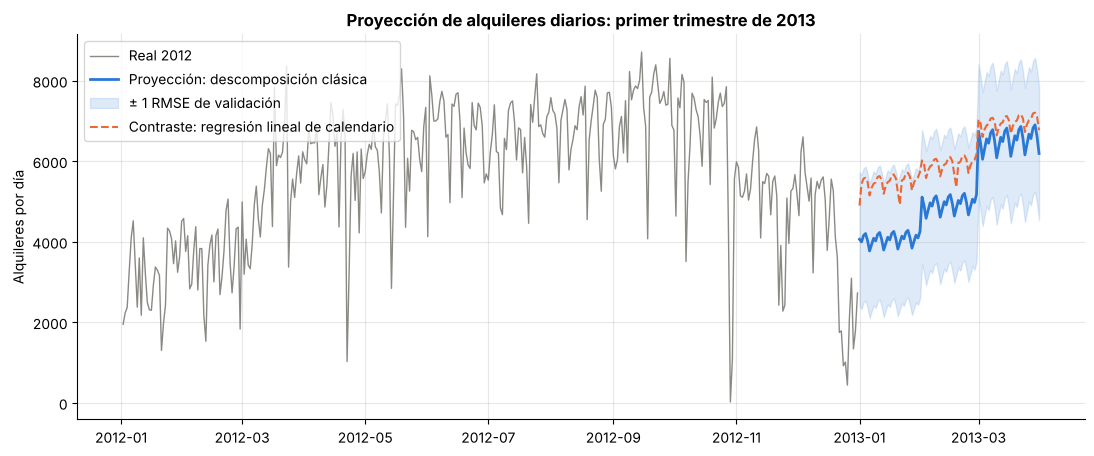

In [47]:
fechas_2013 = pd.date_range('2013-01-01', periods=90, freq='D')
proy_desc = proyectar_descomposicion(tend_total, idx_mes_total, idx_dia_total, fechas_2013, len(serie))

feriados_2013 = pd.to_datetime(['2013-01-01', '2013-01-21', '2013-02-18'])
X_2013 = pd.DataFrame({'tendencia': np.arange(len(serie), len(serie) + 90), 'mes': fechas_2013.month,
                       'dia_semana': fechas_2013.dayofweek, 'holiday': fechas_2013.isin(feriados_2013).astype(int)},
                      index=fechas_2013)
X_2013['workingday'] = ((X_2013['dia_semana'] < 5) & (X_2013['holiday'] == 0)).astype(int)
ml_cal_total = Pipeline([('procesado', prep_cal), ('estimación', LinearRegression())]).fit(Xs, serie)
proy_ml = pd.Series(ml_cal_total.predict(X_2013), index=fechas_2013)

rmse_val = tabla_errores.loc['1. Descomposición clásica', 'RMSE']
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(serie.index[-365:], serie.iloc[-365:], color=GRIS, lw=1, label='Real 2012')
ax.plot(fechas_2013, proy_desc, color=AZUL, lw=2, label='Proyección: descomposición clásica')
ax.fill_between(fechas_2013, proy_desc - rmse_val, proy_desc + rmse_val, color=AZUL, alpha=0.15,
                label='± 1 RMSE de validación')
ax.plot(fechas_2013, proy_ml, color=NARANJA, lw=1.5, ls='--', label='Contraste: regresión lineal de calendario')
ax.set(title='Proyección de alquileres diarios: primer trimestre de 2013', ylabel='Alquileres por día')
ax.legend(loc='upper left')
plt.show()

In [48]:
real_q1_2012 = serie['2012-01':'2012-03'].groupby(serie['2012-01':'2012-03'].index.month).sum()
proy_mensual = pd.DataFrame({
    'Real 2012 (mismo mes)': real_q1_2012.values,
    'Proyección 2013 - descomposición': proy_desc.groupby(proy_desc.index.month).sum().values,
    'Proyección 2013 - regresión calendario': proy_ml.groupby(proy_ml.index.month).sum().values,
    'Promedio diario proyectado (descomp.)': proy_desc.groupby(proy_desc.index.month).mean().values,
}, index=['Enero', 'Febrero', 'Marzo'])
proy_mensual.loc['Trimestre'] = [proy_mensual.iloc[:, 0].sum(), proy_mensual.iloc[:, 1].sum(),
                                 proy_mensual.iloc[:, 2].sum(), proy_desc.mean()]
proy_mensual['Variación vs 2012 (%)'] = (proy_mensual['Proyección 2013 - descomposición'] /
                                         proy_mensual['Real 2012 (mismo mes)'] - 1) * 100
proy_mensual.round(0)

,Real 2012 (mismo mes),Proyección 2013 - descomposición,Proyección 2013 - regresión calendario,Promedio diario proyectado (descomp.),Variación vs 2012 (%)
Enero,"96,744.000","126,190.000","169,570.000","4,071.000",30.000
Febrero,"103,137.000","138,464.000","165,724.000","4,945.000",34.000
Marzo,"164,875.000","202,407.000","215,864.000","6,529.000",23.000
Trimestre,"364,756.000","467,061.000","551,158.000","5,190.000",28.000


**Lectura de la proyección.** La descomposición proyecta para el primer trimestre de 2013 unos **467.000 alquileres**, un **28% más** que el primer trimestre de 2012, con una demanda diaria que sube de ≈ 4.070 en enero a ≈ 4.950 en febrero y ≈ 6.530 en marzo (salida del valle invernal). Un 28% de crecimiento es coherente con la desaceleración observada (el crecimiento interanual del último trimestre de 2012 ya estaba por debajo del de los meses anteriores).

La regresión lineal de calendario proyecta bastante más (≈ 551.000, +51%), pero en la validación ya sobreestimaba un 11% por tratar la estacionalidad como aditiva; se toma como **escenario optimista**, no como pronóstico central.

Cautelas para el uso:

- La tendencia lineal supone que el crecimiento continúa al ritmo promedio de 2011-2012; si la desaceleración sigue, la demanda real puede quedar por debajo: **riesgo a la baja**.
- La variación diaria por clima es grande (banda de ± 1 RMSE ≈ ± 1.660 alquileres por día): en invierno, unos pocos días de nieve pueden mover el total mensual de forma significativa.
- Marzo concentra el 43% del trimestre proyectado y es el mes con mayor incertidumbre: el clima define cuándo arranca la temporada.

# Etapa 6. Conclusiones y recomendaciones

**Para el responsable de operaciones y la gerencia:**

1. **Programar la flota y el personal por franja horaria y tipo de día, no por promedio diario.** Las seis horas pico de los días hábiles (7-9 h y 17-19 h) son solo el 17% de las horas del año pero concentran el 36% de los viajes, con una demanda 2,7 veces mayor que el resto. La redistribución de bicicletas hacia las estaciones de origen de esos viajes debe estar terminada antes de las 7 h y repetirse a media tarde. En fines de semana y feriados, concentrar la disponibilidad entre las 11 y las 17 h. Las madrugadas (0 a 5 h), con apenas el 3% de los viajes, son la ventana natural para mantenimiento y reposición.

2. **Usar la estimación de demanda por hora para la operación diaria, con un margen de seguridad en horas pico.** La estimación horaria tiene un error promedio de unas 22 bicicletas por hora, sobre una demanda que en las horas pico supera las 500. El error es mayor justamente en esas horas y en las tardes de fin de semana (hasta unas 50 bicicletas), por lo que conviene planificar con un colchón de flota en esas franjas en lugar de ajustar al número exacto.

3. **Incorporar el pronóstico del clima a la planificación semanal.** Con lluvia o nieve la demanda cae casi a la mitad (−46%) y el frío la deprime de manera marcada; conocer el clima del día reduce en torno a un 17% el error de la estimación diaria. Los días con pronóstico de mal tiempo son oportunidades para reducir personal de redistribución, adelantar mantenimiento preventivo y retirar bicicletas para reparación; los días cálidos y despejados requieren refuerzo.

4. **Planificar el año con la estacionalidad: preparar la flota en invierno para la temporada alta.** Un día de enero mueve el 60% de la demanda de un día promedio, mientras que de mayo a septiembre la demanda supera el promedio entre un 16% y un 34%. El primer trimestre es el momento para concentrar compras, reparaciones mayores y vacaciones del personal, y la flota completa debe estar disponible desde abril. Para enero-marzo de 2013 se esperan unos 467.000 alquileres (+28% respecto del mismo trimestre de 2012), de los cuales más del 40% se concentran en marzo.

5. **Evaluar el desempeño con comparaciones interanuales o desestacionalizadas y revisar el pronóstico todos los meses.** El aumento de 2011 a 2012 (+65%) es crecimiento real de uso, no un efecto del calendario; en cambio, la caída de julio a enero es estacional y no debe leerse como pérdida de clientes (descontando la estación, en ese período la demanda creció un 41%). Como el ritmo de crecimiento se moderó hacia fines de 2012, la proyección de continuidad puede quedar alta: conviene actualizarla cada mes con los datos nuevos y tener un plan de flota alternativo para un escenario de menor crecimiento.